# 02 — Loan Repayment Analysis

**In simple terms:** This notebook looks at loan payments and tries to understand how people repay their loans (for example, how often payments are late and how payment amounts behave).

**Input (what we use):** CSV files from `data/raw/` — mainly `loan_payments.csv`, plus `accounts.csv`, `customers.csv`, and `branches.csv` to add context.

**Output (what we get):** A combined table (`loans_full`) that links each payment to account/customer/branch info, plus summaries, charts, and a loan-level summary (`loan_level`).

**Key links we use (checked in `01_inventory.ipynb`):**
- `loan_payments.loan_id` → `accounts.account_id`
- `accounts.customer_id` → `customers.customer_id`
- `accounts.branch_id` → `branches.branch_id`

**Steps in this notebook:**
1. Load the data
2. Join tables together
3. Check the joins worked
4. Look at basic repayment numbers
5. Compare late payments across groups
6. (Next sections) check outliers, trends over time, and loan-level summaries


In [20]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt 
import seaborn as sns

pd.set_option('display.max_columns', 100)
pd.set_option('display.float_format', '{:.2f}'.format)

raw_path = "../data/raw"

from pathlib import Path
FIG_DIR = Path('../reports/figures')
FIG_DIR.mkdir(parents=True, exist_ok=True)


## 1) Load data

**In simple terms:** We open the files we need so we can work with them.

**Input:** `loan_payments.csv`, `accounts.csv`, `customers.csv`, `branches.csv` from `../data/raw/`.

**Output:** Four tables (DataFrames) in memory and a quick preview of `loan_payments`. The printed shapes tell us how many rows and columns each file has.


In [21]:
loan_payments = pd.read_csv(os.path.join(raw_path, "loan_payments.csv"))
accounts = pd.read_csv(os.path.join(raw_path, "accounts.csv"))
customers = pd.read_csv(os.path.join(raw_path, "customers.csv"))
branches = pd.read_csv(os.path.join(raw_path, "branches.csv"))

print("loan_payments:", loan_payments.shape)
print("accounts:", accounts.shape)
print("customers:", customers.shape)
print("branches:", branches.shape)

loan_payments.head()


loan_payments: (600000, 7)
accounts: (95000, 7)
customers: (60000, 12)
branches: (150, 6)


,payment_id,loan_id,payment_date,amount_paid,principal_component,interest_component,late_payment_flag
0,1,21070,2020-05-06,8144.05,5930.89,2213.16,0
1,2,17959,2011-09-23,6128.01,4406.78,1721.23,0
2,3,7239,2025-02-25,27946.17,25195.76,2750.41,0
3,4,9993,2015-10-04,5715.37,4082.41,1632.96,0
4,5,5487,2017-07-26,10119.72,9474.29,645.43,0


**Insight (simple terms):** This table shows a few example payment records. Each row is one payment. Look at columns like `loan_id`, `payment_date`, `amount_paid`, and `late_payment_flag` to understand what one record contains.


## 2) Build the merged dataset

**In simple terms:** We connect payment records to the account, customer, and branch they belong to.

**Input:** The 4 tables loaded above.

**Output:** One bigger table called `loans_full`. Each row is still a payment, but now it can include extra details (like account/customer/branch info) when the IDs match.


In [22]:
# Join loan payments to accounts
loans_acc = loan_payments.merge(
    accounts,
    left_on="loan_id",
    right_on="account_id",
    how="left",
    suffixes=("_payment", "_acc")
)

# Add customer details
loans_cust = loans_acc.merge(
    customers,
    on="customer_id",
    how="left",
    suffixes=("", "_cust")
)

# Add branch details
loans_full = loans_cust.merge(
    branches,
    on="branch_id",
    how="left",
    suffixes=("", "_branch")
)

print("Merged shape:", loans_full.shape)
loans_full.head()


Merged shape: (600000, 30)


,payment_id,loan_id,payment_date,amount_paid,principal_component,interest_component,late_payment_flag,account_id,customer_id,branch_id,account_type,balance,open_date,status,name,gender,date_of_birth,city,state,phone,email,occupation,annual_income,join_date,credit_score,branch_name,city_branch,state_branch,opened_date,ifsc_code
0,1,21070,2020-05-06,8144.05,5930.89,2213.16,0,21070,46478,148,Savings,16517.33,2014-09-01,Active,Mary Bose,Female,1963-06-18,Lucknow,Uttar Pradesh,9301902646,customer46477@mailbank.com,Retired,459719,2016-05-05,665,Bengaluru Branch 4,Bengaluru,Karnataka,1998-07-04,BNK0000147
1,2,17959,2011-09-23,6128.01,4406.78,1721.23,0,17959,25135,25,Salary,54354.38,2018-11-20,Active,Jennifer Joshi,Male,1966-07-05,Chandigarh,Punjab,9958410642,customer25134@mailbank.com,Self Employed,1151942,2022-05-12,584,Bhopal Branch 7,Bhopal,Madhya Pradesh,2012-06-02,BNK0000024
2,3,7239,2025-02-25,27946.17,25195.76,2750.41,0,7239,25807,150,NRI,90528.84,2026-04-11,Active,Meera Rao,Male,2004-12-05,Hyderabad,Telangana,9239820486,customer25806@mailbank.com,Self Employed,1761078,2018-01-31,839,Mumbai Branch 6,Mumbai,Maharashtra,2008-11-06,BNK0000149
3,4,9993,2015-10-04,5715.37,4082.41,1632.96,0,9993,51012,43,Savings,137182.70,2014-01-31,Active,Robert Chopra,Female,1973-05-10,Bhopal,Madhya Pradesh,9709472239,customer51011@mailbank.com,Salaried - Government,1335343,2023-09-19,852,Chandigarh Branch 7,Chandigarh,Punjab,2004-01-17,BNK0000042
4,5,5487,2017-07-26,10119.72,9474.29,645.43,0,5487,12152,27,Current,27446.62,2020-07-19,Active,Karen Garcia,Female,1960-09-07,Nagpur,Maharashtra,9102512381,customer12151@mailbank.com,Freelancer,353753,2021-06-24,692,Kolkata Branch 9,Kolkata,West Bengal,2012-12-04,BNK0000026


**Insight (simple terms):** This preview shows payments after joining with account/customer/branch info. If you see customer or branch details filled in, the joins are working. If many of these extra fields are empty (NaN), the join may not have matched well.


## 3) Check merge quality

**In simple terms:** We make sure the “connecting” step worked.

**Input:** `loans_full` (the merged table).

**Output:**
- Counts of missing (null) IDs — if these are high, some payments didn’t find a matching account/customer/branch.
- A quick check of whether `amount_paid` is close to `principal_component + interest_component` (small differences can happen; big ones may need a look).


In [23]:
key_cols = ["loan_id", "account_id", "customer_id", "branch_id"]
for c in key_cols:
    if c in loans_full.columns:
        nulls = loans_full[c].isna().sum()
        pct = (nulls / len(loans_full) * 100) if len(loans_full) else 0
        print(f"{c}: {nulls:,} nulls ({pct:.2f}%)")

# Quick sanity: do payment components add up?
if {"amount_paid", "principal_component", "interest_component"}.issubset(loans_full.columns):
    diff = (loans_full["amount_paid"] - (loans_full["principal_component"] + loans_full["interest_component"]))
    print("\nAmount component difference (amount_paid - principal - interest):")
    print(diff.describe())


loan_id: 0 nulls (0.00%)
account_id: 0 nulls (0.00%)
customer_id: 0 nulls (0.00%)
branch_id: 0 nulls (0.00%)

Amount component difference (amount_paid - principal - interest):
count   600000.00
mean         0.00
std          0.00
min         -0.00
25%          0.00
50%          0.00
75%          0.00
max          0.00
dtype: float64


**Insight (simple terms):** These results tell you how well the tables matched. Low (or 0%) nulls in key IDs mean most payments were successfully linked. The amount-difference summary helps you spot payments where the parts don’t add up to the total (worth a closer look if differences are large).


## 4) Basic repayment metrics

**In simple terms:** We calculate simple headline numbers about repayments.

**Input:** `loans_full`.

**Output:**
- Total number of payments, how many were late, and the late payment rate (%).
- A summary of `amount_paid` (typical values, min/max, etc.).


In [24]:
# Late payment rate
if "late_payment_flag" in loans_full.columns:
    total = len(loans_full)
    late = loans_full["late_payment_flag"].sum()
    rate = (late / total * 100) if total else 0
    print(f"Total payments: {total:,}")
    print(f"Late payments: {late:,}")
    print(f"Late payment rate: {rate:.2f}%")

# Payment amount summary
if "amount_paid" in loans_full.columns:
    print("\nAmount paid summary:")
    display(loans_full["amount_paid"].describe().to_frame().T)


Total payments: 600,000
Late payments: 72,038
Late payment rate: 12.01%

Amount paid summary:


,count,mean,std,min,25%,50%,75%,max
amount_paid,600000.00,10397.46,9856.84,526.27,3409.95,7361.83,14138.02,147281.59


**Insight (simple terms):** This gives the overall picture: how many payments exist, how many were late, and the late rate (%). A higher % means late payments are more common in this dataset. Compare this later with group/time breakdowns to find patterns.


## 5) Late payments by segment (quick view)

**In simple terms:** We compare late payment rates across different groups to see where lateness is higher or lower.

**Input:** `loans_full` and the `late_payment_flag` column.

**Output:** Small tables showing, for each group (like `account_type`, `state`, `city`, `occupation`, `gender`): number of payments, number of late payments, and late rate (%). This is a quick look, not a final conclusion.


In [25]:
def late_rate_by(df, col):
    if col not in df.columns or "late_payment_flag" not in df.columns:
        return None
    g = df.groupby(col, dropna=False).agg(
        payments=("late_payment_flag", "size"),
        late_payments=("late_payment_flag", "sum"),
    )
    g["late_rate_%"] = (g["late_payments"] / g["payments"] * 100).round(2)
    return g.sort_values("late_rate_%", ascending=False)

for col in ["account_type", "state", "city", "occupation", "gender"]:
    res = late_rate_by(loans_full, col)
    if res is not None:
        print(f"\n=== Late rate by {col} (top 10) ===")
        display(res.head(10))



=== Late rate by account_type (top 10) ===


,payments,late_payments,late_rate_%
account_type,,,
Salary,89674,10825,12.07
Savings,305684,36857,12.06
Fixed Deposit,58648,6998,11.93
Current,117873,14050,11.92
NRI,28121,3308,11.76



=== Late rate by state (top 10) ===


,payments,late_payments,late_rate_%
state,,,
Telangana,39215,4828,12.31
West Bengal,41476,5081,12.25
Kerala,39028,4736,12.13
Uttar Pradesh,40927,4948,12.09
Maharashtra,117246,14129,12.05
Rajasthan,36962,4440,12.01
Delhi,40411,4834,11.96
Gujarat,39399,4706,11.94
Punjab,41033,4886,11.91



=== Late rate by city (top 10) ===


,payments,late_payments,late_rate_%
city,,,
Hyderabad,39215,4828,12.31
Kolkata,41476,5081,12.25
Nagpur,39115,4751,12.15
Kochi,39028,4736,12.13
Lucknow,40927,4948,12.09
Pune,38028,4590,12.07
Jaipur,36962,4440,12.01
Delhi,40411,4834,11.96
Ahmedabad,39399,4706,11.94



=== Late rate by occupation (top 10) ===


,payments,late_payments,late_rate_%
occupation,,,
Business Owner,83365,10059,12.07
Self Employed,84641,10200,12.05
Student,87011,10488,12.05
Salaried - Private,85922,10347,12.04
Retired,84582,10187,12.04
Salaried - Government,87867,10488,11.94
Freelancer,86612,10269,11.86



=== Late rate by gender (top 10) ===


,payments,late_payments,late_rate_%
gender,,,
Other,13186,1609,12.20
Male,315816,37916,12.01
Female,270998,32513,12.00


**Insight (simple terms):** These tables compare lateness across groups (like account type or location). Focus on groups with enough payments to be meaningful. Big differences in late rate may suggest where to investigate further, but they don’t prove the cause.


## 6) Notes / Next steps

**What we built:** a merged loan repayment dataset (`loans_full`) combining payments with account, customer, and branch context.

**Next steps to consider:**
- Convert `payment_date` and other date fields to `datetime` and analyze trends over time
- Aggregate to the loan level (e.g., total paid, % late, first/last payment) if you have a true loan identifier beyond `loan_id`
- Compare late payment rates across segments with more robust checks (sample sizes, missingness)
- Save a processed dataset to `data/processed/` for reuse (ensure no sensitive raw data is committed)


## 7) Outlier detection and handling

**In simple terms:** This section is all in one place: we (A) do quick checks, (B) explore outliers with charts, and (C) apply a recommended, reproducible way to flag/cap them.

**Input:** `loans_full` (merged dataset).  
**Output:** Outlier summaries/charts, flags/capped columns in `loans_full_processed`, and a saved processed file in `data/processed/`.

### 7A) Quick checks

**In simple terms:** We look for unusually high or low values in payment amounts using percentiles and the IQR rule.

**Input:** `loans_full` payment amount columns.  
**Output:** A summary table with typical values and IQR bounds, plus counts of flagged outliers. Flags are for **review**, not automatic deletion.


In [26]:
import matplotlib.pyplot as plt

numeric_cols = [c for c in ["amount_paid", "principal_component", "interest_component"] if c in loans_full.columns]

def outlier_summary(df, col):
    s = df[col].dropna()
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    mask = (s < lower) | (s > upper)
    return {
        "column": col,
        "count": int(s.shape[0]),
        "min": s.min(),
        "p01": s.quantile(0.01),
        "p25": q1,
        "median": s.median(),
        "p75": q3,
        "p99": s.quantile(0.99),
        "max": s.max(),
        "iqr_lower": lower,
        "iqr_upper": upper,
        "outliers_iqr": int(mask.sum()),
        "outliers_iqr_%": round(mask.mean() * 100, 2),
    }

if numeric_cols:
    summary = pd.DataFrame([outlier_summary(loans_full, c) for c in numeric_cols])
    display(summary)
else:
    print("No expected numeric payment columns found.")


,column,count,min,p01,p25,median,p75,p99,max,iqr_lower,iqr_upper,outliers_iqr,outliers_iqr_%
0,amount_paid,600000,526.27,706.19,3409.95,7361.83,14138.02,46058.50,147281.59,-12682.14,30230.12,29458,4.91
1,principal_component,600000,500.03,581.77,2798.77,6032.06,11571.88,37260.30,110436.89,-10360.89,24731.53,28867,4.81
2,interest_component,600000,25.40,72.36,505.98,1177.95,2507.29,10287.22,36844.70,-2495.99,5509.26,39394,6.57


**Insight (simple terms):** This table shows what “typical” values look like (percentiles) and how many values fall outside the IQR bounds. In money-related fields, a long tail is common—use this to decide which extreme values to review, not to delete automatically.


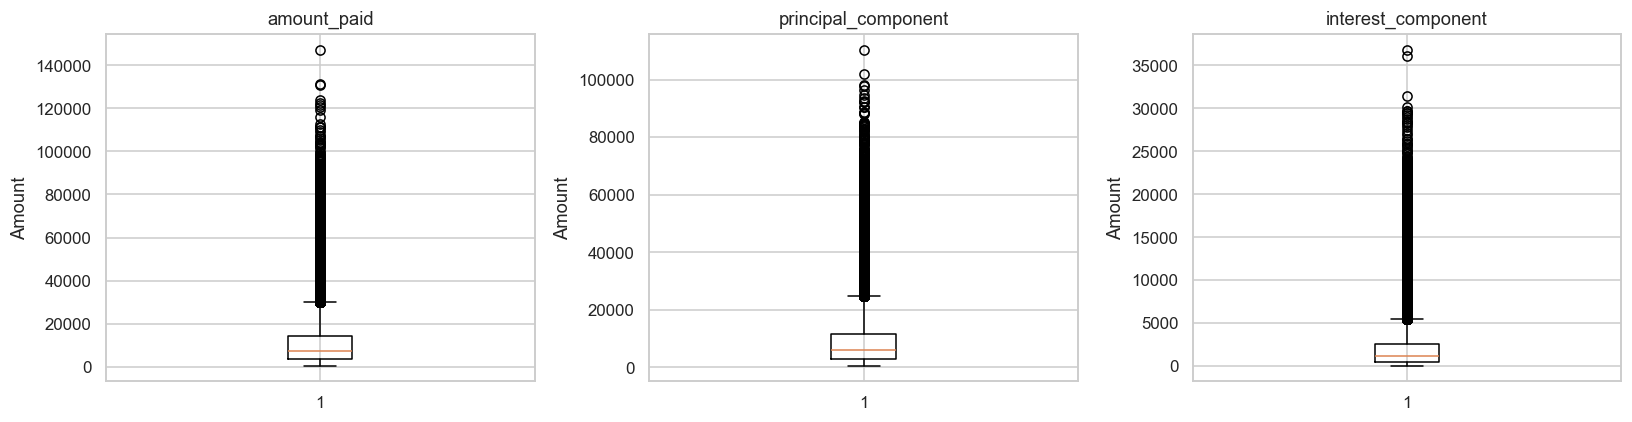

In [27]:
# Quick visual check (boxplots)
if numeric_cols:
    fig, axes = plt.subplots(1, len(numeric_cols), figsize=(5 * len(numeric_cols), 4))
    if len(numeric_cols) == 1:
        axes = [axes]
    for ax, col in zip(axes, numeric_cols):
        ax.boxplot(loans_full[col].dropna(), vert=True)
        ax.set_title(col)
        ax.set_ylabel("Amount")
    plt.tight_layout()
    plt.show()


In [28]:
# Inspect top extreme values (context matters)
for col in numeric_cols:
    print(f"\n=== Top 10 highest {col} ===")
    display(loans_full.nlargest(10, col)[[c for c in ["payment_id","loan_id","payment_date","amount_paid","principal_component","interest_component","late_payment_flag"] if c in loans_full.columns]])



=== Top 10 highest amount_paid ===


,payment_id,loan_id,payment_date,amount_paid,principal_component,interest_component,late_payment_flag
405307,405308,13751,2025-04-29,147281.59,110436.89,36844.70,1
292902,292903,9738,2015-01-09,131411.12,101910.37,29500.75,0
12083,12084,17178,2012-12-25,130646.53,94528.43,36118.10,0
148322,148323,4826,2015-10-07,123738.76,92293.00,31445.76,0
239368,239369,4177,2021-11-08,122289.06,92602.76,29686.30,0
535261,535262,3750,2017-11-20,121724.36,97721.50,24002.86,1
92691,92692,4623,2025-06-03,120684.36,90504.04,30180.32,0
66119,66120,19236,2023-06-22,119233.18,90438.37,28794.81,0
87361,87362,19638,2018-09-22,115838.18,96547.36,19290.82,0
253758,253759,7778,2023-06-06,112580.26,98015.80,14564.46,0



=== Top 10 highest principal_component ===


,payment_id,loan_id,payment_date,amount_paid,principal_component,interest_component,late_payment_flag
405307,405308,13751,2025-04-29,147281.59,110436.89,36844.70,1
292902,292903,9738,2015-01-09,131411.12,101910.37,29500.75,0
253758,253759,7778,2023-06-06,112580.26,98015.80,14564.46,0
535261,535262,3750,2017-11-20,121724.36,97721.50,24002.86,1
87361,87362,19638,2018-09-22,115838.18,96547.36,19290.82,0
12083,12084,17178,2012-12-25,130646.53,94528.43,36118.10,0
567024,567025,629,2016-03-18,98480.79,93550.16,4930.63,0
239368,239369,4177,2021-11-08,122289.06,92602.76,29686.30,0
148322,148323,4826,2015-10-07,123738.76,92293.00,31445.76,0
147213,147214,5525,2014-12-16,97781.88,92118.53,5663.35,1



=== Top 10 highest interest_component ===


,payment_id,loan_id,payment_date,amount_paid,principal_component,interest_component,late_payment_flag
405307,405308,13751,2025-04-29,147281.59,110436.89,36844.70,1
12083,12084,17178,2012-12-25,130646.53,94528.43,36118.10,0
148322,148323,4826,2015-10-07,123738.76,92293.00,31445.76,0
92691,92692,4623,2025-06-03,120684.36,90504.04,30180.32,0
239368,239369,4177,2021-11-08,122289.06,92602.76,29686.30,0
477880,477881,841,2015-10-15,111502.93,81857.68,29645.25,0
292902,292903,9738,2015-01-09,131411.12,101910.37,29500.75,0
339912,339913,1981,2025-05-02,104536.71,75038.91,29497.80,0
247891,247892,8555,2015-02-07,110003.57,80754.12,29249.45,1
414418,414419,6731,2025-05-31,111278.93,82328.22,28950.71,0


### 7B) Enhanced analysis with visualizations

**In simple terms:** We check outliers more carefully and use charts to see the shape of the data.

**Input:** `loans_full` (payment amounts and, if available, `balance`, `annual_income`, `credit_score`).  
**Output:** Percentile/IQR summary, distribution + boxplot charts for each column, and tables of extreme rows to review in context.


In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110

# Candidate numeric columns to check (only if present)
candidate_cols = [
    'amount_paid', 'principal_component', 'interest_component',
    'balance', 'annual_income', 'credit_score'
]
cols = [c for c in candidate_cols if c in loans_full.columns]
print('Checking columns:', cols)

def iqr_flags(s):
    s = s.dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    mask = (s < lower) | (s > upper)
    return lower, upper, mask

rows = []
for c in cols:
    lower, upper, mask = iqr_flags(loans_full[c])
    s = loans_full[c].dropna()
    rows.append({
        'column': c,
        'n': int(s.shape[0]),
        'p01': s.quantile(0.01),
        'p50': s.quantile(0.50),
        'p99': s.quantile(0.99),
        'iqr_lower': lower,
        'iqr_upper': upper,
        'outliers_n': int(mask.sum()),
        'outliers_%': round(mask.mean() * 100, 2),
    })

outlier_tbl = pd.DataFrame(rows)
display(outlier_tbl)


Checking columns: ['amount_paid', 'principal_component', 'interest_component', 'balance', 'annual_income', 'credit_score']


,column,n,p01,p50,p99,iqr_lower,iqr_upper,outliers_n,outliers_%
0,amount_paid,600000,706.19,7361.83,46058.50,-12682.14,30230.12,29458,4.91
1,principal_component,600000,581.77,6032.06,37260.30,-10360.89,24731.53,28867,4.81
2,interest_component,600000,72.36,1177.95,10287.22,-2495.99,5509.26,39394,6.57
3,balance,600000,970.34,31641.99,206594.32,-61531.37,138242.87,29293,4.88
4,annual_income,600000,180579.00,1835830.00,3463889.00,-1476839.12,5142813.88,0,0.00
5,credit_score,600000,305.00,604.00,893.00,-3.00,1205.00,0,0.00


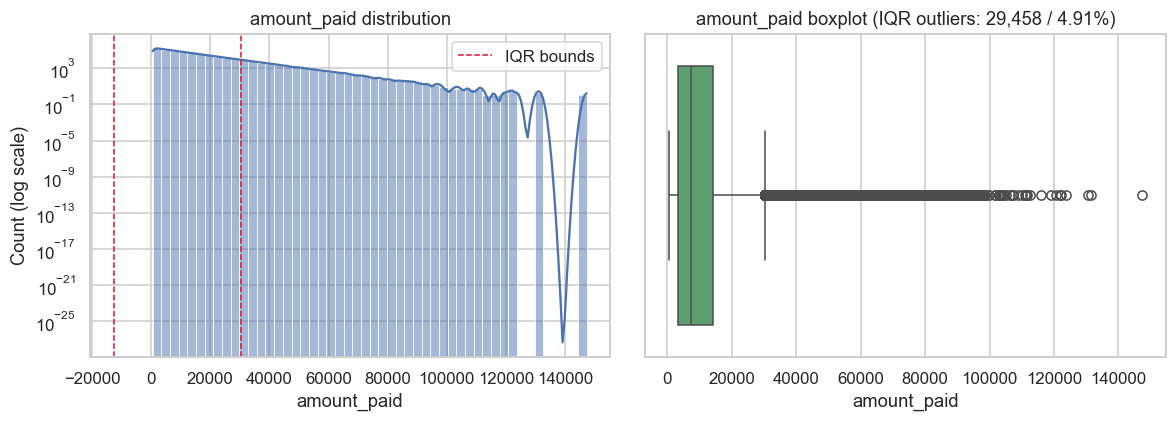

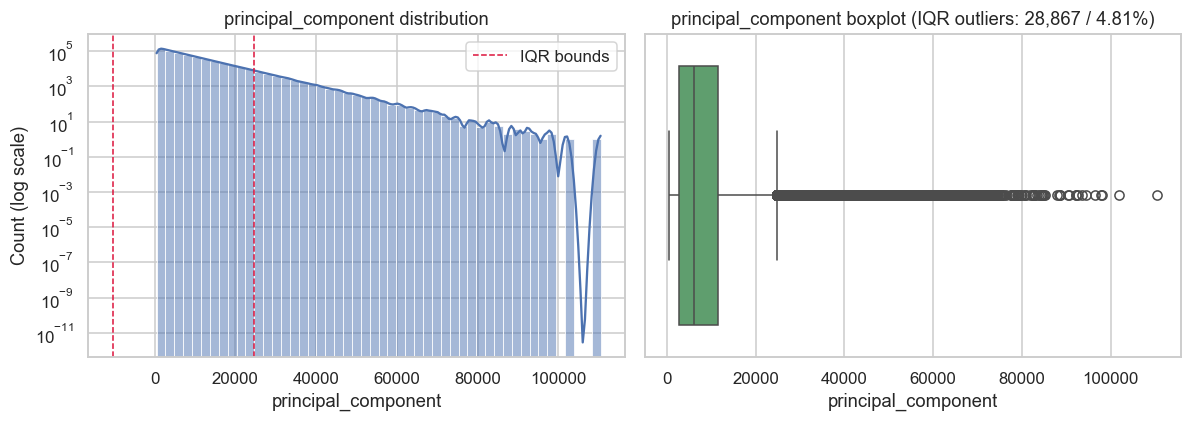

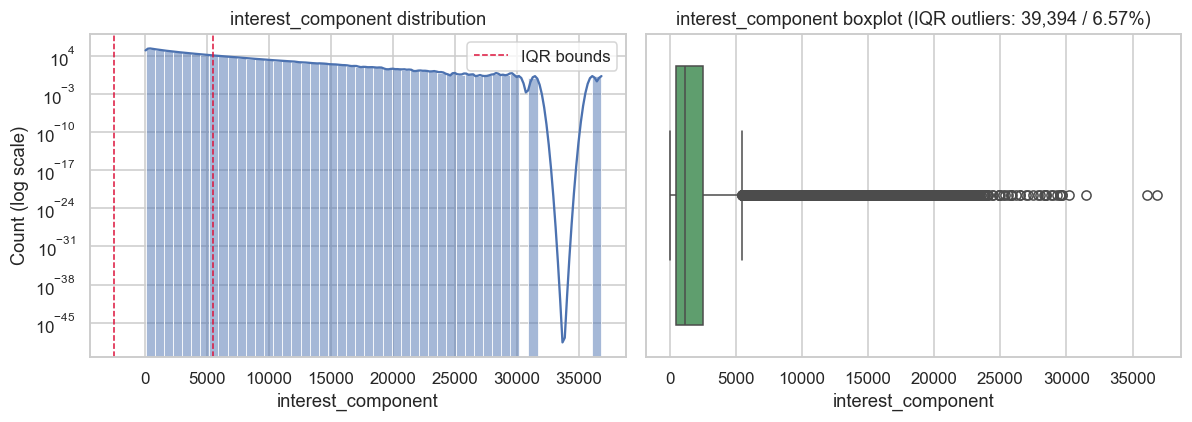

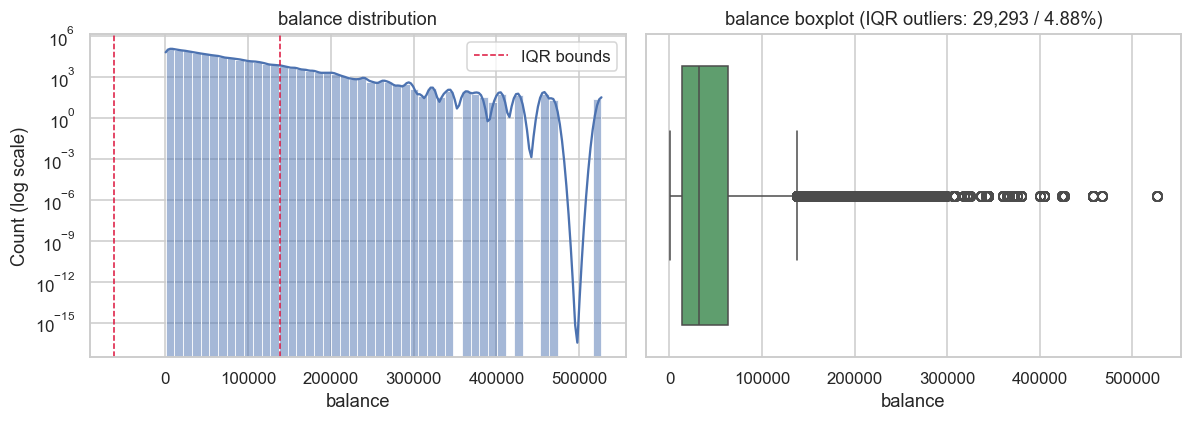

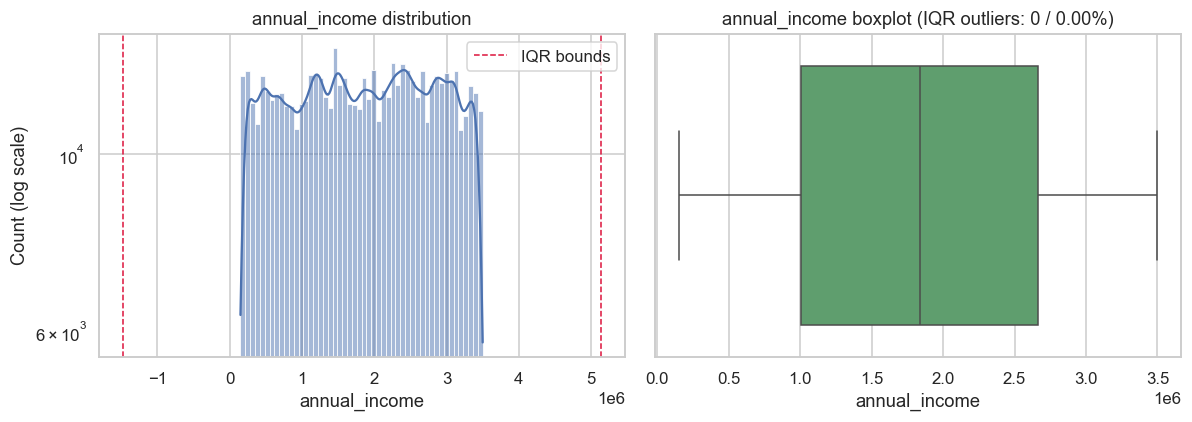

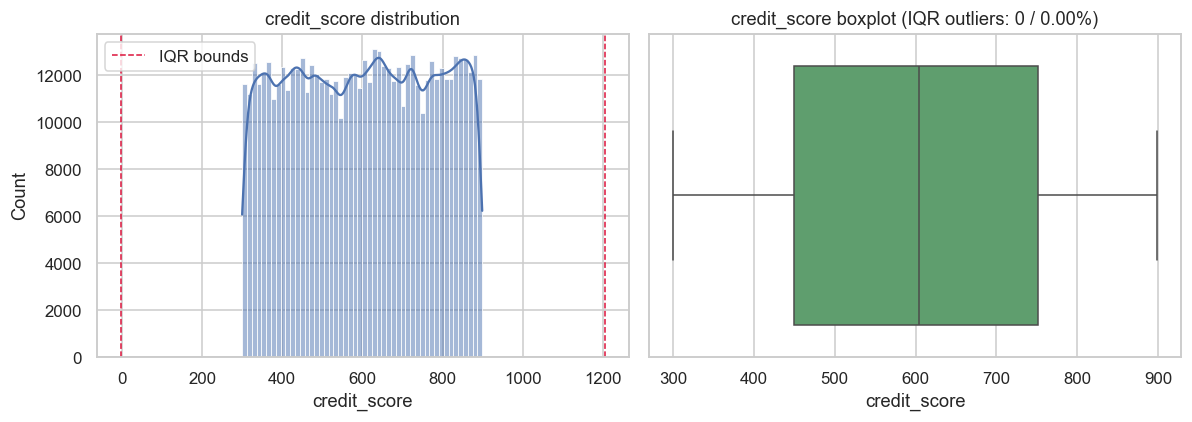

In [30]:
# Distribution + boxplot panels (good quality visuals)
for c in cols:
    s = loans_full[c].dropna()
    lower, upper, mask = iqr_flags(loans_full[c])
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))

    # Histogram (use log scale for highly skewed monetary fields)
    skewed = c in ['amount_paid', 'principal_component', 'interest_component', 'balance', 'annual_income']
    sns.histplot(s, bins=50, kde=True, ax=axes[0], color='#4C72B0')
    axes[0].axvline(lower, color='crimson', linestyle='--', linewidth=1, label='IQR bounds')
    axes[0].axvline(upper, color='crimson', linestyle='--', linewidth=1)
    axes[0].set_title(f'{c} distribution')
    axes[0].set_xlabel(c)
    axes[0].legend()
    if skewed:
        axes[0].set_yscale('log')
        axes[0].set_ylabel('Count (log scale)')

    # Boxplot
    sns.boxplot(x=s, ax=axes[1], color='#55A868')
    axes[1].set_title(f'{c} boxplot (IQR outliers: {mask.sum():,} / {mask.mean()*100:.2f}%)')
    axes[1].set_xlabel(c)

    plt.tight_layout()
    if c in ['amount_paid','balance','annual_income','credit_score']:
        plt.savefig(FIG_DIR / f'outlier_dist_{c}.png', bbox_inches='tight')
    plt.show()


**Insight (simple terms):** The charts show how values are spread out. A tall peak with a long right tail means most values are small/moderate but a few are very large. Points beyond the dashed IQR bounds are flagged as unusual—check whether they make sense in context.


In [31]:
# Focused view: extreme tails (top/bottom examples) for review
review_cols = [c for c in ['payment_id','loan_id','customer_id','payment_date','amount_paid','principal_component','interest_component','balance','annual_income','credit_score','late_payment_flag'] if c in loans_full.columns]
for c in cols:
    print(f'\n=== Highest 10: {c} ===')
    display(loans_full.nlargest(10, c)[review_cols].head(10))
    # For fields where low values can be notable, show lowest 10 too
    if c in ['credit_score', 'balance']:
        print(f'=== Lowest 10: {c} ===')
        display(loans_full.nsmallest(10, c)[review_cols].head(10))



=== Highest 10: amount_paid ===


,payment_id,loan_id,customer_id,payment_date,amount_paid,principal_component,interest_component,balance,annual_income,credit_score,late_payment_flag
405307,405308,13751,21741,2025-04-29,147281.59,110436.89,36844.70,44553.93,709005,800,1
292902,292903,9738,38669,2015-01-09,131411.12,101910.37,29500.75,49163.74,2696653,843,0
12083,12084,17178,23934,2012-12-25,130646.53,94528.43,36118.10,23216.78,854355,556,0
148322,148323,4826,10271,2015-10-07,123738.76,92293.00,31445.76,64610.84,2805431,719,0
239368,239369,4177,21206,2021-11-08,122289.06,92602.76,29686.30,96809.62,3292580,545,0
535261,535262,3750,23185,2017-11-20,121724.36,97721.50,24002.86,76846.12,1112693,354,1
92691,92692,4623,33001,2025-06-03,120684.36,90504.04,30180.32,27355.05,2747107,465,0
66119,66120,19236,7058,2023-06-22,119233.18,90438.37,28794.81,31059.86,1902464,366,0
87361,87362,19638,25726,2018-09-22,115838.18,96547.36,19290.82,18889.17,1099261,867,0
253758,253759,7778,19975,2023-06-06,112580.26,98015.80,14564.46,45495.45,185656,653,0



=== Highest 10: principal_component ===


,payment_id,loan_id,customer_id,payment_date,amount_paid,principal_component,interest_component,balance,annual_income,credit_score,late_payment_flag
405307,405308,13751,21741,2025-04-29,147281.59,110436.89,36844.70,44553.93,709005,800,1
292902,292903,9738,38669,2015-01-09,131411.12,101910.37,29500.75,49163.74,2696653,843,0
253758,253759,7778,19975,2023-06-06,112580.26,98015.80,14564.46,45495.45,185656,653,0
535261,535262,3750,23185,2017-11-20,121724.36,97721.50,24002.86,76846.12,1112693,354,1
87361,87362,19638,25726,2018-09-22,115838.18,96547.36,19290.82,18889.17,1099261,867,0
12083,12084,17178,23934,2012-12-25,130646.53,94528.43,36118.10,23216.78,854355,556,0
567024,567025,629,55347,2016-03-18,98480.79,93550.16,4930.63,21966.85,425801,720,0
239368,239369,4177,21206,2021-11-08,122289.06,92602.76,29686.30,96809.62,3292580,545,0
148322,148323,4826,10271,2015-10-07,123738.76,92293.00,31445.76,64610.84,2805431,719,0
147213,147214,5525,35586,2014-12-16,97781.88,92118.53,5663.35,62916.52,1826986,598,1



=== Highest 10: interest_component ===


,payment_id,loan_id,customer_id,payment_date,amount_paid,principal_component,interest_component,balance,annual_income,credit_score,late_payment_flag
405307,405308,13751,21741,2025-04-29,147281.59,110436.89,36844.70,44553.93,709005,800,1
12083,12084,17178,23934,2012-12-25,130646.53,94528.43,36118.10,23216.78,854355,556,0
148322,148323,4826,10271,2015-10-07,123738.76,92293.00,31445.76,64610.84,2805431,719,0
92691,92692,4623,33001,2025-06-03,120684.36,90504.04,30180.32,27355.05,2747107,465,0
239368,239369,4177,21206,2021-11-08,122289.06,92602.76,29686.30,96809.62,3292580,545,0
477880,477881,841,30553,2015-10-15,111502.93,81857.68,29645.25,2425.44,465908,394,0
292902,292903,9738,38669,2015-01-09,131411.12,101910.37,29500.75,49163.74,2696653,843,0
339912,339913,1981,32533,2025-05-02,104536.71,75038.91,29497.80,14565.91,2862345,853,0
247891,247892,8555,58016,2015-02-07,110003.57,80754.12,29249.45,44556.06,2742674,612,1
414418,414419,6731,18715,2025-05-31,111278.93,82328.22,28950.71,52341.39,1232610,481,0


... (6 outputs left out)


=== Highest 10: credit_score ===


,payment_id,loan_id,customer_id,payment_date,amount_paid,principal_component,interest_component,balance,annual_income,credit_score,late_payment_flag
192,193,17496,16039,2013-01-25,22141.73,19677.65,2464.08,34169.18,2041174,899,0
393,394,10004,13458,2014-11-30,14429.90,12023.62,2406.28,11923.49,1511438,899,1
1760,1761,2397,294,2016-03-16,2348.90,1944.16,404.74,96482.38,1770598,899,0
1814,1815,11654,30310,2023-09-23,19030.32,15561.47,3468.85,98408.87,782523,899,0
2104,2105,2766,3031,2020-12-07,16092.83,11651.67,4441.16,171951.70,1179283,899,0
4070,4071,9542,6022,2023-08-04,4979.78,3835.59,1144.19,4783.40,3132796,899,0
4303,4304,10140,14206,2021-04-22,6654.10,4771.75,1882.35,119347.53,3031450,899,0
4562,4563,17006,36363,2024-11-08,7750.33,6159.64,1590.69,72731.14,2412016,899,0
4638,4639,5957,23907,2019-04-22,9995.05,7598.04,2397.01,15577.54,1949865,899,0
5307,5308,5572,20029,2012-12-05,2061.07,1670.06,391.01,5246.86,1320038,899,0


=== Lowest 10: credit_score ===


,payment_id,loan_id,customer_id,payment_date,amount_paid,principal_component,interest_component,balance,annual_income,credit_score,late_payment_flag
55,56,880,23586,2022-09-23,8019.62,6527.95,1491.67,967.99,1530501,300,0
617,618,16224,58536,2022-05-26,3889.62,3347.88,541.74,18901.84,1631897,300,1
1035,1036,1078,50134,2015-10-29,6237.35,5491.14,746.21,145194.43,750721,300,0
1148,1149,18432,56132,2010-10-26,19824.26,15259.25,4565.01,94208.37,1224059,300,0
1168,1169,4112,40208,2026-01-28,2755.51,2274.88,480.63,44759.35,1296077,300,0
2918,2919,3817,57293,2011-10-14,6527.00,5541.11,985.89,14180.43,1490466,300,1
2964,2965,10657,46266,2011-02-13,39773.26,29174.19,10599.07,51190.83,671683,300,0
3631,3632,10823,42495,2019-06-28,16305.58,12013.44,4292.14,12614.22,967689,300,0
3939,3940,8540,6321,2021-07-07,3952.15,3014.28,937.87,106387.47,1490766,300,0
4451,4452,16415,18827,2017-06-25,21169.07,16402.01,4767.06,11640.53,2334426,300,0


**Insight (simple terms):** These rows are the most extreme examples for each field. Review them to see if they look realistic (e.g., a large one-time payment) or suspicious (possible data issue). The extra columns help you understand the context of each extreme case.


**How to interpret:**
- A high IQR-outlier % on skewed monetary fields is common; inspect extremes rather than removing them blindly.
- Use domain rules where possible (e.g., negative balances may be valid/invalid depending on product; `credit_score` ranges).
- If you decide to cap/fix values, do it in a reproducible way and save cleaned outputs to `data/processed/` (kept out of git).


### 7C) Recommended handling (flag + cap) and save

**Recommendation (simple & safe):**
- **Flag** potential outliers using the IQR rule (`*__is_outlier_iqr`) so you can review/filter them.
- **Cap (winsorize) at the 1st–99th percentile** for skewed monetary fields (`*__capped_p1_p99`): `amount_paid`, `principal_component`, `interest_component`, `balance`, `annual_income`.
- Keep **`credit_score` unchanged** but still flag unusual values.

**Why:** Keeps all rows, reduces distortion from extreme tails, and is reproducible. Raw data in `data/raw/` stays untouched.

**Input:** `loans_full`  
**Output:** `loans_full_processed` and `data/processed/loans_full_processed.csv` (gitignored).


In [32]:
# Recommended outlier handling
# - Flag using IQR (for review)
# - Winsorize (cap) at p1/p99 for skewed monetary fields
import numpy as np

loans_full_processed = loans_full.copy()

flag_cols = [c for c in ['amount_paid','principal_component','interest_component','balance','annual_income','credit_score'] if c in loans_full_processed.columns]
cap_cols = [c for c in ['amount_paid','principal_component','interest_component','balance','annual_income'] if c in loans_full_processed.columns]

rules = {}
for c in flag_cols:
    s = loans_full_processed[c]
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lower_iqr, upper_iqr = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    loans_full_processed[f'{c}__is_outlier_iqr'] = ((s < lower_iqr) | (s > upper_iqr)).astype(int)
    rules[c] = {'iqr_lower': lower_iqr, 'iqr_upper': upper_iqr}

for c in cap_cols:
    p1, p99 = loans_full_processed[c].quantile(0.01), loans_full_processed[c].quantile(0.99)
    loans_full_processed[f'{c}__capped_p1_p99'] = loans_full_processed[c].clip(lower=p1, upper=p99)
    rules[c] = {**rules.get(c, {}), 'p1': p1, 'p99': p99}

# Quick summary of what changed
summary = []
for c in flag_cols:
    flag = f'{c}__is_outlier_iqr'
    summary.append({
        'column': c,
        'flagged_outliers_n': int(loans_full_processed[flag].sum()),
        'flagged_outliers_%': round(loans_full_processed[flag].mean()*100, 2),
        'capped': c in cap_cols
    })
display(pd.DataFrame(summary))

print('\nRules applied (sample):')
for c in ['amount_paid','balance','annual_income','credit_score']:
    if c in rules:
        print(c, {k: (float(v) if pd.notna(v) else None) for k,v in rules[c].items()})


,column,flagged_outliers_n,flagged_outliers_%,capped
0,amount_paid,29458,4.91,True
1,principal_component,28867,4.81,True
2,interest_component,39394,6.57,True
3,balance,29293,4.88,True
4,annual_income,0,0.00,True
5,credit_score,0,0.00,False



Rules applied (sample):
amount_paid {'iqr_lower': -12682.1425, 'iqr_upper': 30230.1175, 'p1': 706.1896999999999, 'p99': 46058.49700000002}
balance {'iqr_lower': -61531.369999999995, 'iqr_upper': 138242.87, 'p1': 970.34, 'p99': 206594.32}
annual_income {'iqr_lower': -1476839.125, 'iqr_upper': 5142813.875, 'p1': 180579.0, 'p99': 3463889.0}
credit_score {'iqr_lower': -3.0, 'iqr_upper': 1205.0}


In [33]:
# Save processed dataset (gitignored)
from pathlib import Path

processed_path = Path(raw_path).parent / 'processed'
processed_path.mkdir(parents=True, exist_ok=True)
out = processed_path / 'loans_full_processed.csv'
loans_full_processed.to_csv(out, index=False)
print(f'Saved: {out} ({loans_full_processed.shape[0]:,} rows, {loans_full_processed.shape[1]} cols)')


Saved: ..\data\processed\loans_full_processed.csv (600,000 rows, 41 cols)


**Insight (simple terms):** The new file keeps the original columns and adds extra columns: `*__is_outlier_iqr` (1 = flagged for review) and `*__capped_p1_p99` for skewed monetary fields. Use the **capped** columns when you want more stable summaries/visuals; use the **flags** when you want to investigate unusual cases. If a capped value changes an important business result, review those records before finalizing conclusions.


## 9) Time-based analysis

**In simple terms:** We look at how payments change over time (month by month).

**Input:** `loans_full`, especially `payment_date`, `amount_paid`, and `late_payment_flag`.

**Output:**
- Dates converted into a proper date format.
- The earliest and latest payment dates found.
- Charts showing monthly payment counts, total money paid, and late payment rate.
- A table of the most recent months.


In [39]:
# Convert date columns where present
date_cols = [c for c in ["payment_date", "open_date", "date_of_birth", "join_date", "issue_date", "expiry_date"] if c in loans_full.columns]
for c in date_cols:
    loans_full[c] = pd.to_datetime(loans_full[c], errors='coerce')

print('Converted date columns:', date_cols)
if 'payment_date' in loans_full.columns:
    print('payment_date range:', loans_full['payment_date'].min(), 'to', loans_full['payment_date'].max())
    print('payment_date nulls:', loans_full['payment_date'].isna().sum())


Converted date columns: ['payment_date', 'open_date', 'date_of_birth', 'join_date']
payment_date range: 2010-02-01 00:00:00 to 2026-05-31 00:00:00
payment_date nulls: 0


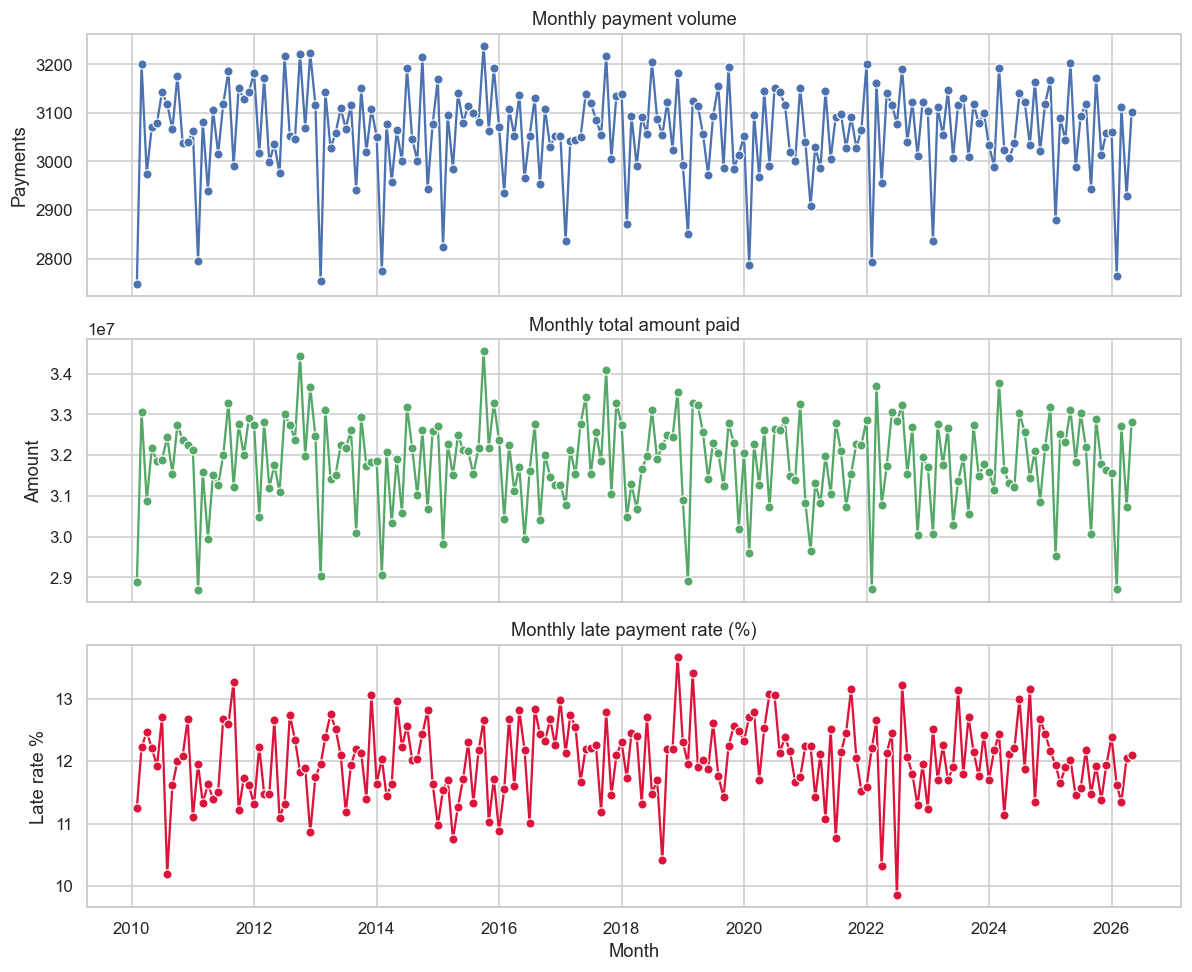

,payment_month,payments,total_paid,late_payments,late_rate_%
184,2025-06-01,2988,31835136.41,342,11.45
185,2025-07-01,3093,33027596.98,358,11.57
186,2025-08-01,3119,32188211.03,380,12.18
187,2025-09-01,2943,30060146.68,338,11.48
188,2025-10-01,3172,32875970.68,378,11.92
189,2025-11-01,3014,31783471.68,343,11.38
190,2025-12-01,3058,31632969.72,365,11.94
191,2026-01-01,3061,31553151.52,379,12.38
192,2026-02-01,2764,28702103.80,321,11.61
193,2026-03-01,3111,32717118.96,353,11.35


In [40]:

if 'payment_date' in loans_full.columns and loans_full['payment_date'].notna().any():
    tmp = loans_full.dropna(subset=['payment_date']).copy()
    tmp['payment_month'] = tmp['payment_date'].dt.to_period('M').dt.to_timestamp()

    monthly = tmp.groupby('payment_month').agg(
        payments=('payment_id', 'count') if 'payment_id' in tmp.columns else ('payment_date', 'size'),
        total_paid=('amount_paid', 'sum') if 'amount_paid' in tmp.columns else ('payment_date', 'size'),
        late_payments=('late_payment_flag', 'sum') if 'late_payment_flag' in tmp.columns else ('payment_date', 'size'),
    ).reset_index()
    if 'late_payments' in monthly.columns and 'payments' in monthly.columns:
        monthly['late_rate_%'] = (monthly['late_payments'] / monthly['payments'] * 100).round(2)

    fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True)
    sns.lineplot(data=monthly, x='payment_month', y='payments', ax=axes[0], marker='o')
    axes[0].set_title('Monthly payment volume')
    axes[0].set_ylabel('Payments')

    if 'total_paid' in monthly.columns:
        sns.lineplot(data=monthly, x='payment_month', y='total_paid', ax=axes[1], marker='o', color='#55A868')
        axes[1].set_title('Monthly total amount paid')
        axes[1].set_ylabel('Amount')

    if 'late_rate_%' in monthly.columns:
        sns.lineplot(data=monthly, x='payment_month', y='late_rate_%', ax=axes[2], marker='o', color='crimson')
        axes[2].set_title('Monthly late payment rate (%)')
        axes[2].set_ylabel('Late rate %')
        axes[2].set_xlabel('Month')

    plt.tight_layout()
    plt.savefig(FIG_DIR / 'monthly_repayment_trends.png', bbox_inches='tight')
    plt.show()

    display(monthly.tail(12))
else:
    print('payment_date not available for time analysis.')


**Insight (simple terms):** These time charts show how repayments behave month by month. Look for trends (going up/down), sudden jumps/drops, or seasonal patterns. The late-rate line helps you see if lateness is improving, worsening, or stable over time.


### 9A) Monthly patterns by year (Jan–Dec view)

**In simple terms:** Instead of one long timeline (which gets crowded over 17 years), we look at months **within each year** (January to December). This makes seasonal patterns and year-to-year differences easier to see.

**Input:** `payment_date`, `amount_paid`, and `late_payment_flag` from `loans_full`.

**Output:** A heatmap showing late payment rate by **year × month** (easy to scan many years), plus a focused view for storytelling.


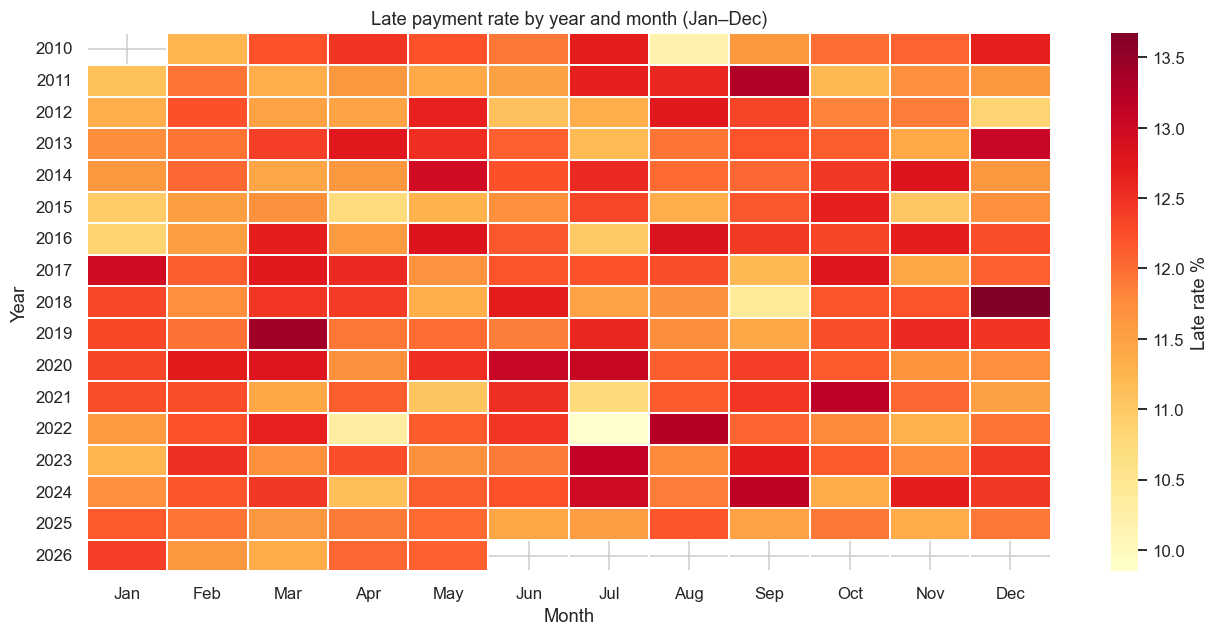

,year,month,payments,total_paid,late_payments,late_rate_%
184,2025,6,2988,31835136.41,342,11.45
185,2025,7,3093,33027596.98,358,11.57
186,2025,8,3119,32188211.03,380,12.18
187,2025,9,2943,30060146.68,338,11.48
188,2025,10,3172,32875970.68,378,11.92
189,2025,11,3014,31783471.68,343,11.38
190,2025,12,3058,31632969.72,365,11.94
191,2026,1,3061,31553151.52,379,12.38
192,2026,2,2764,28702103.80,321,11.61
193,2026,3,3111,32717118.96,353,11.35


In [41]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110

if 'payment_date' in loans_full.columns and loans_full['payment_date'].notna().any():
    t = loans_full.dropna(subset=['payment_date']).copy()
    t['year'] = t['payment_date'].dt.year
    t['month'] = t['payment_date'].dt.month
    t['month_name'] = t['payment_date'].dt.strftime('%b')

    ym = t.groupby(['year','month']).agg(
        payments=('payment_id','count') if 'payment_id' in t.columns else ('payment_date','size'),
        total_paid=('amount_paid','sum') if 'amount_paid' in t.columns else ('payment_date','size'),
        late_payments=('late_payment_flag','sum') if 'late_payment_flag' in t.columns else ('payment_date','size'),
    ).reset_index()
    ym['late_rate_%'] = (ym['late_payments'] / ym['payments'] * 100)

    # Heatmap: years x months (Jan-Dec)
    pivot = ym.pivot(index='year', columns='month', values='late_rate_%')
    pivot = pivot.reindex(columns=range(1,13))
    plt.figure(figsize=(12, max(4, 0.35 * len(pivot.index))))
    sns.heatmap(pivot, annot=False, cmap='YlOrRd', linewidths=0.3, cbar_kws={'label': 'Late rate %'})
    plt.title('Late payment rate by year and month (Jan–Dec)')
    plt.xlabel('Month')
    plt.ylabel('Year')
    plt.xticks(ticks=np.arange(12)+0.5, labels=['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'], rotation=0)
    plt.tight_layout()
    try:
        plt.savefig(FIG_DIR / 'late_rate_heatmap_year_month.png', bbox_inches='tight')
    except Exception:
        pass
    plt.show()

    display(ym.sort_values(['year','month']).tail(12))
else:
    print('payment_date not available.')


**Insight (simple terms):** The heatmap lets you scan all years at once. Darker colors mean a higher late payment rate for that month/year. Look for repeating patterns in the same months (seasonality) or specific years that stand out as better or worse.


### 9B) Pairwise year comparison (Jan–Dec), from 2010 onward

**In simple terms:** With many years of data, one chart can get crowded. Here we compare **two years at a time** (in order) using the same Jan–Dec view, so each comparison is easy to read.

**Input:** `payment_date`, `late_payment_flag`, and `amount_paid` (if available) from `loans_full`.

**Output:** For each pair (e.g., 2010 vs 2011, 2012 vs 2013, … up to the last available year), we create two side-by-side charts:
- **Late payment rate** by month (Jan–Dec)
- **Payment volume** by month (Jan–Dec)
A small difference table is shown for each pair. Figures are also saved to `reports/figures/`.


Years included (>=2010): [2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026]
Note: last year has no pair: 2026
Pairs: [(2010, 2011), (2012, 2013), (2014, 2015), (2016, 2017), (2018, 2019), (2020, 2021), (2022, 2023), (2024, 2025)]


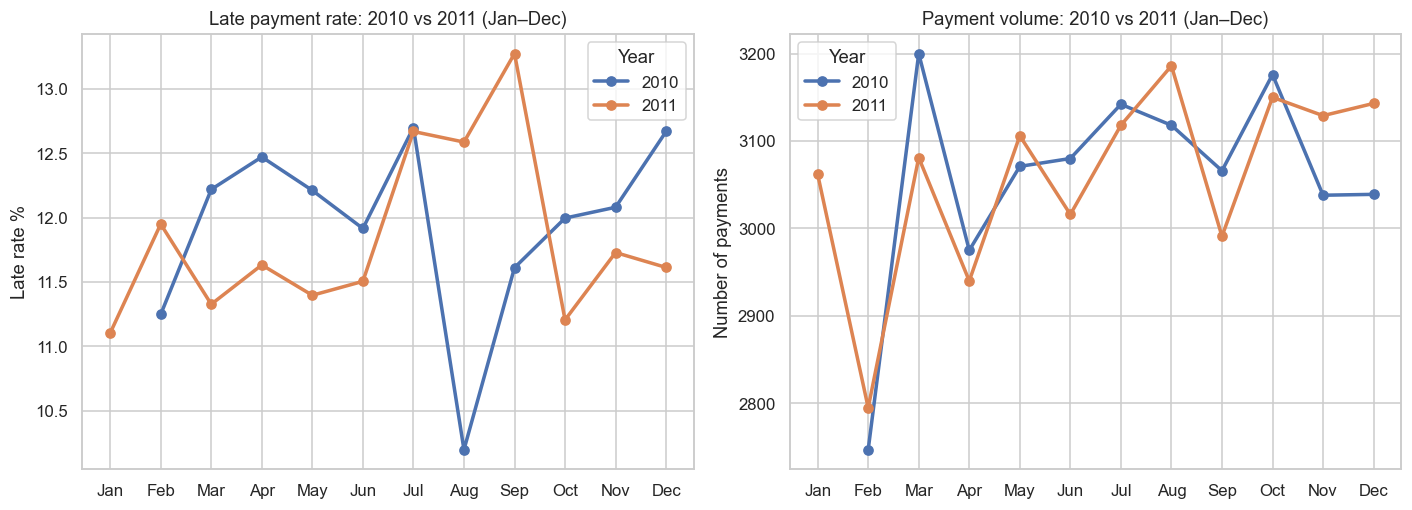

,month_name,payments_2010,payments_2011,late_rate_%_2010,late_rate_%_2011,late_rate_diff_pp_(y2-y1)
0,Jan,NaN,3062.00,NaN,11.10,NaN
1,Feb,2747.00,2795.00,11.25,11.95,0.70
2,Mar,3200.00,3081.00,12.22,11.33,-0.89
3,Apr,2975.00,2940.00,12.47,11.63,-0.84
4,May,3071.00,3106.00,12.21,11.40,-0.81
5,Jun,3080.00,3016.00,11.92,11.51,-0.41
6,Jul,3142.00,3118.00,12.70,12.67,-0.03
7,Aug,3118.00,3186.00,10.20,12.59,2.39
8,Sep,3066.00,2991.00,11.61,13.27,1.66
9,Oct,3176.00,3150.00,12.00,11.21,-0.79


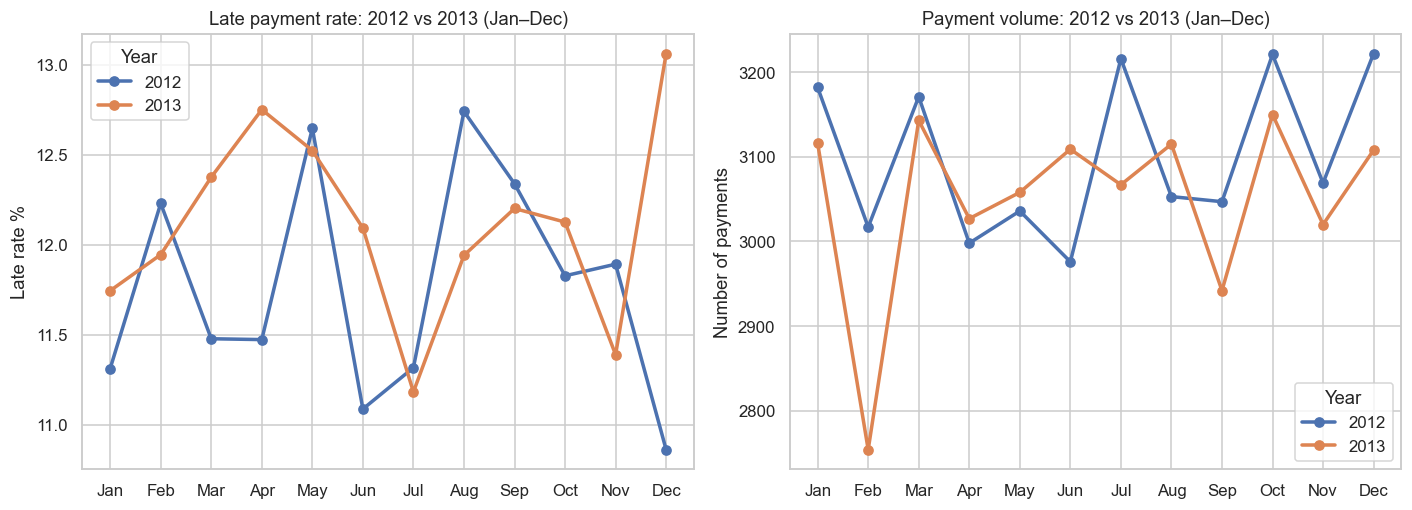

,month_name,payments_2012,payments_2013,late_rate_%_2012,late_rate_%_2013,late_rate_diff_pp_(y2-y1)
0,Jan,3182.00,3116.00,11.31,11.75,0.43
1,Feb,3017.00,2754.00,12.23,11.95,-0.28
2,Mar,3171.00,3143.00,11.48,12.38,0.90
3,Apr,2998.00,3027.00,11.47,12.75,1.28
4,May,3036.00,3058.00,12.65,12.52,-0.12
5,Jun,2976.00,3109.00,11.09,12.09,1.01
6,Jul,3216.00,3067.00,11.32,11.18,-0.13
7,Aug,3053.00,3115.00,12.74,11.94,-0.80
8,Sep,3047.00,2942.00,12.34,12.20,-0.14
9,Oct,3221.00,3150.00,11.83,12.13,0.30


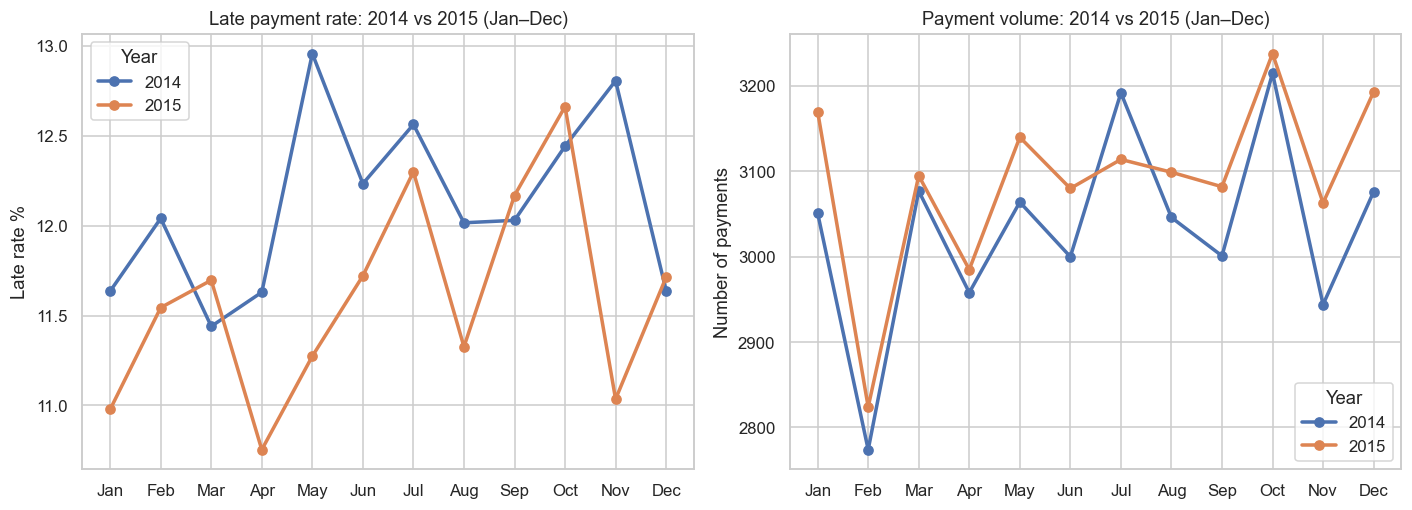

,month_name,payments_2014,payments_2015,late_rate_%_2014,late_rate_%_2015,late_rate_diff_pp_(y2-y1)
0,Jan,3051.00,3170.00,11.64,10.98,-0.66
1,Feb,2774.00,2824.00,12.04,11.54,-0.50
2,Mar,3077.00,3095.00,11.44,11.70,0.26
3,Apr,2958.00,2985.00,11.63,10.75,-0.88
4,May,3064.00,3140.00,12.96,11.27,-1.68
5,Jun,3000.00,3080.00,12.23,11.72,-0.51
6,Jul,3192.00,3114.00,12.56,12.30,-0.26
7,Aug,3046.00,3099.00,12.02,11.33,-0.69
8,Sep,3001.00,3082.00,12.03,12.17,0.14
9,Oct,3215.00,3238.00,12.44,12.66,0.22


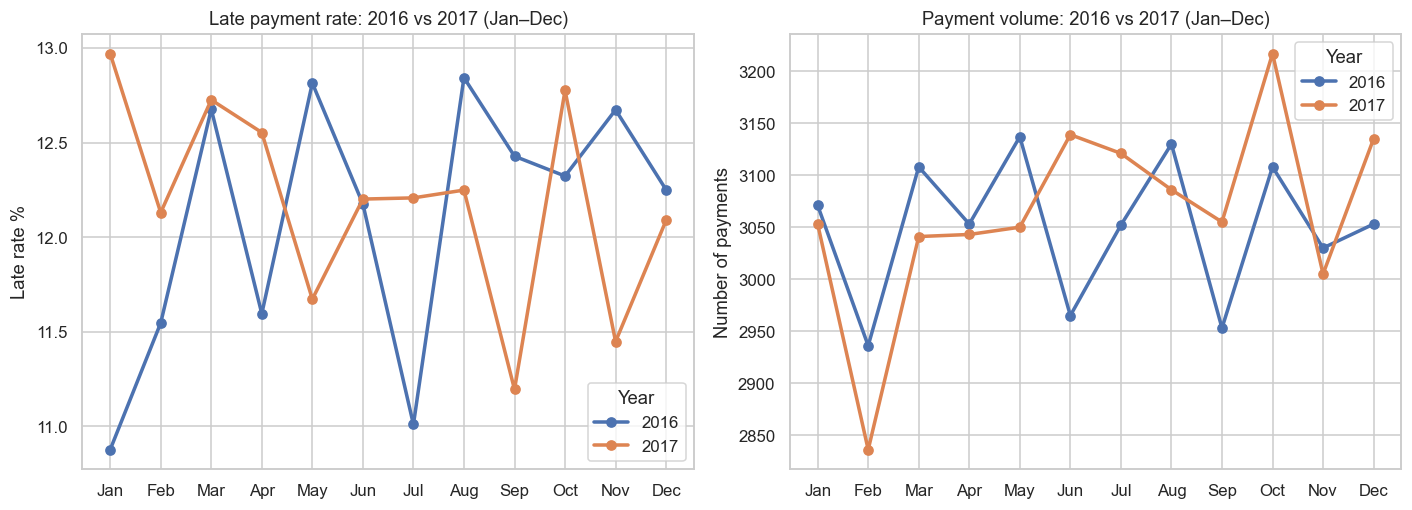

,month_name,payments_2016,payments_2017,late_rate_%_2016,late_rate_%_2017,late_rate_diff_pp_(y2-y1)
0,Jan,3071.00,3053.00,10.88,12.97,2.09
1,Feb,2936.00,2836.00,11.55,12.13,0.58
2,Mar,3108.00,3041.00,12.68,12.73,0.05
3,Apr,3053.00,3043.00,11.60,12.55,0.96
4,May,3137.00,3050.00,12.81,11.67,-1.14
5,Jun,2965.00,3139.00,12.18,12.20,0.03
6,Jul,3052.00,3121.00,11.01,12.21,1.20
7,Aug,3130.00,3086.00,12.84,12.25,-0.59
8,Sep,2953.00,3055.00,12.43,11.19,-1.23
9,Oct,3108.00,3217.00,12.32,12.78,0.45


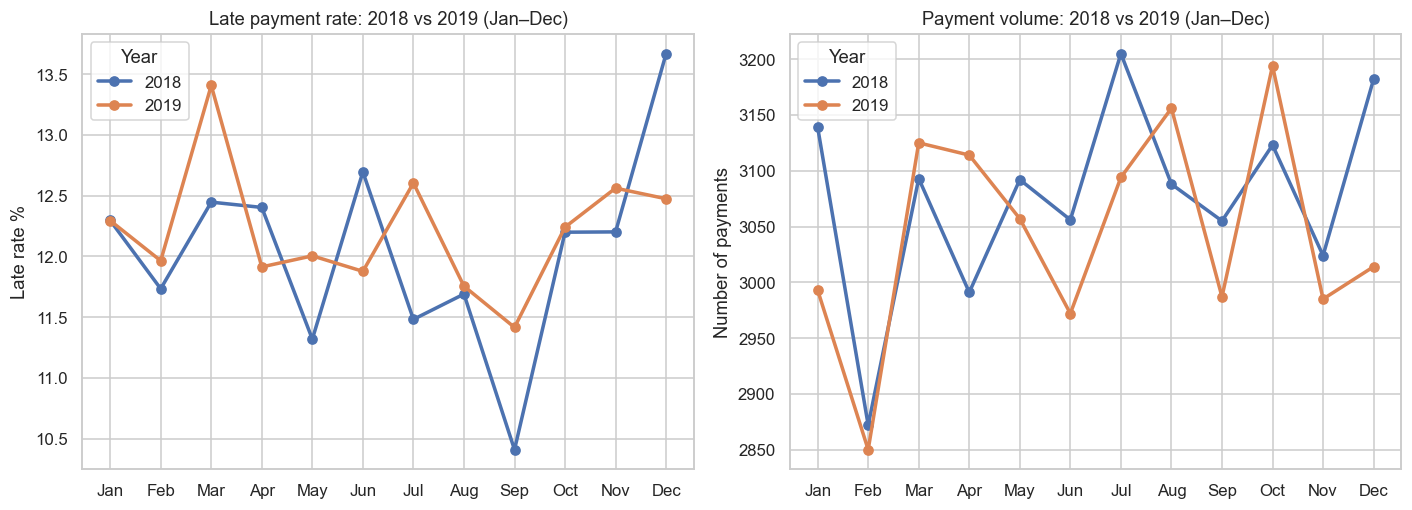

,month_name,payments_2018,payments_2019,late_rate_%_2018,late_rate_%_2019,late_rate_diff_pp_(y2-y1)
0,Jan,3139.00,2993.00,12.30,12.30,-0.00
1,Feb,2872.00,2850.00,11.73,11.96,0.23
2,Mar,3093.00,3125.00,12.45,13.41,0.96
3,Apr,2991.00,3114.00,12.40,11.91,-0.49
4,May,3092.00,3057.00,11.32,12.01,0.69
5,Jun,3056.00,2972.00,12.70,11.88,-0.82
6,Jul,3205.00,3094.00,11.48,12.61,1.12
7,Aug,3088.00,3156.00,11.69,11.76,0.06
8,Sep,3055.00,2987.00,10.41,11.42,1.01
9,Oct,3123.00,3194.00,12.20,12.24,0.04


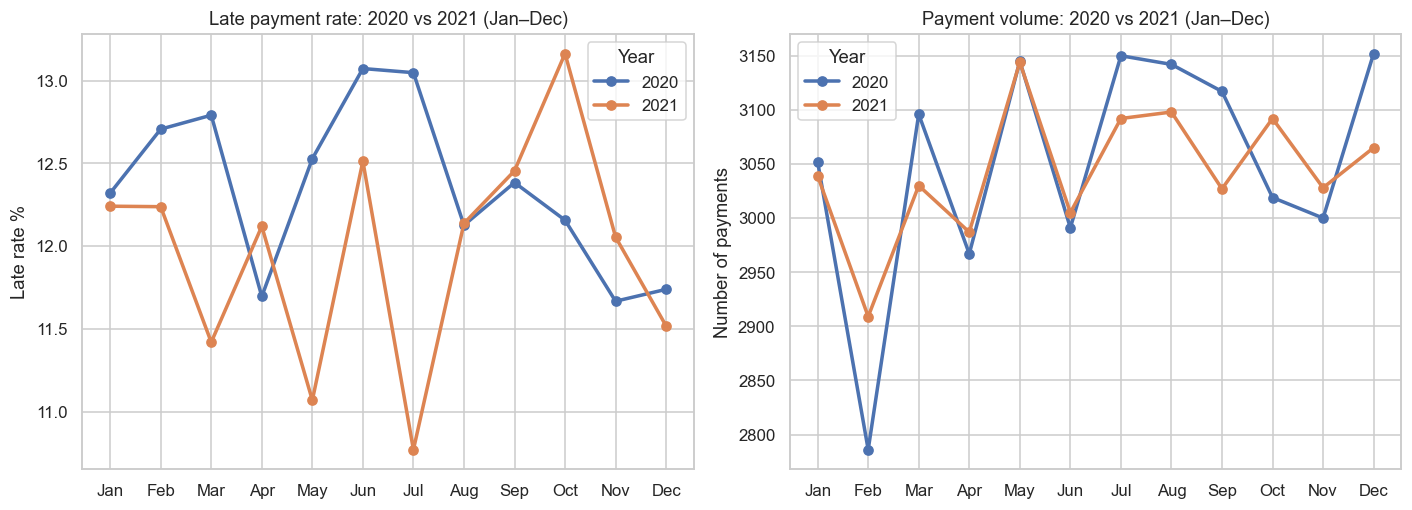

,month_name,payments_2020,payments_2021,late_rate_%_2020,late_rate_%_2021,late_rate_diff_pp_(y2-y1)
0,Jan,3052.00,3039.00,12.32,12.24,-0.08
1,Feb,2786.00,2909.00,12.71,12.24,-0.47
2,Mar,3096.00,3030.00,12.79,11.42,-1.37
3,Apr,2967.00,2987.00,11.70,12.12,0.42
4,May,3145.00,3144.00,12.53,11.07,-1.46
5,Jun,2991.00,3005.00,13.07,12.51,-0.56
6,Jul,3150.00,3092.00,13.05,10.77,-2.28
7,Aug,3142.00,3098.00,12.13,12.14,0.01
8,Sep,3117.00,3027.00,12.38,12.45,0.07
9,Oct,3019.00,3092.00,12.16,13.16,1.01


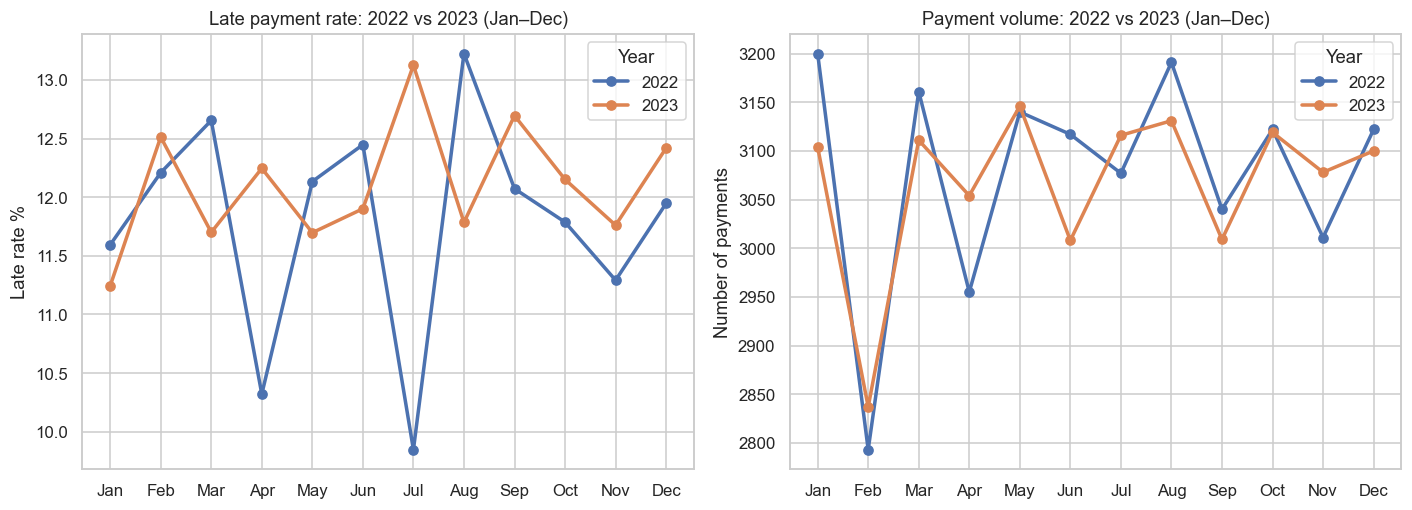

,month_name,payments_2022,payments_2023,late_rate_%_2022,late_rate_%_2023,late_rate_diff_pp_(y2-y1)
0,Jan,3200.00,3104.00,11.59,11.24,-0.35
1,Feb,2793.00,2837.00,12.21,12.51,0.30
2,Mar,3161.00,3111.00,12.65,11.70,-0.95
3,Apr,2955.00,3054.00,10.32,12.25,1.92
4,May,3140.00,3146.00,12.13,11.70,-0.44
5,Jun,3117.00,3008.00,12.45,11.90,-0.55
6,Jul,3077.00,3116.00,9.85,13.13,3.28
7,Aug,3191.00,3131.00,13.22,11.79,-1.44
8,Sep,3040.00,3009.00,12.07,12.70,0.62
9,Oct,3122.00,3119.00,11.79,12.15,0.36


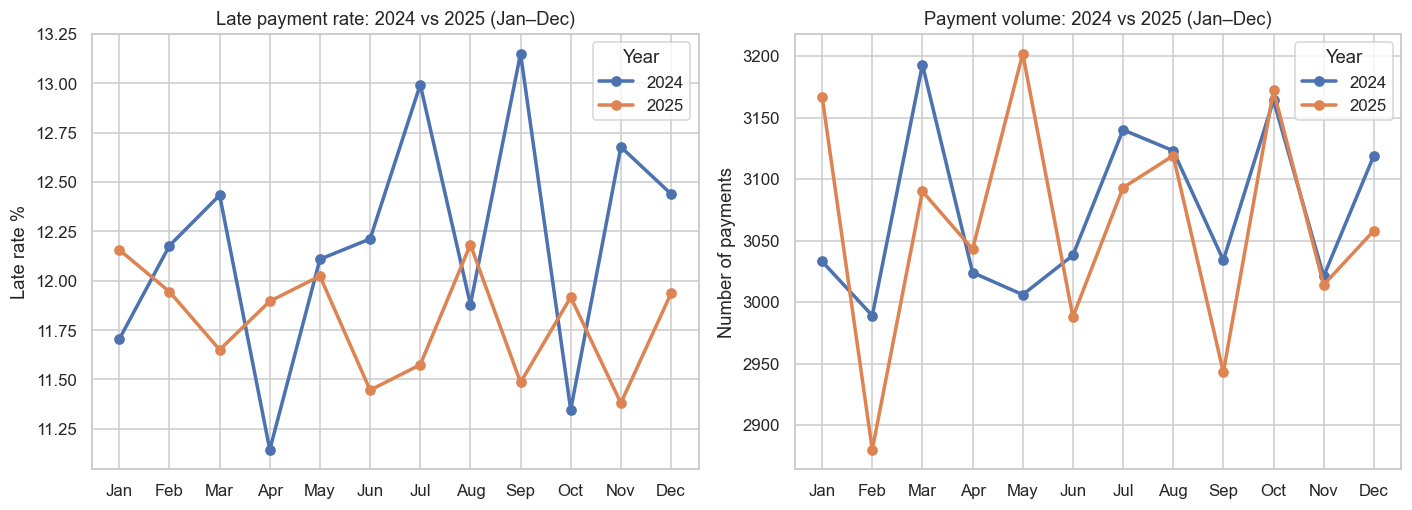

,month_name,payments_2024,payments_2025,late_rate_%_2024,late_rate_%_2025,late_rate_diff_pp_(y2-y1)
0,Jan,3033.00,3167.00,11.70,12.16,0.45
1,Feb,2989.00,2880.00,12.18,11.94,-0.23
2,Mar,3193.00,3090.00,12.43,11.65,-0.78
3,Apr,3024.00,3043.00,11.14,11.90,0.75
4,May,3006.00,3202.00,12.11,12.02,-0.09
5,Jun,3038.00,2988.00,12.21,11.45,-0.77
6,Jul,3140.00,3093.00,12.99,11.57,-1.42
7,Aug,3123.00,3119.00,11.88,12.18,0.30
8,Sep,3034.00,2943.00,13.15,11.48,-1.67
9,Oct,3164.00,3172.00,11.35,11.92,0.57


In [42]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110

if 'payment_date' in loans_full.columns and loans_full['payment_date'].notna().any():
    t = loans_full.dropna(subset=['payment_date']).copy()
    t['year'] = t['payment_date'].dt.year
    t['month'] = t['payment_date'].dt.month
    month_labels = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']

    years = sorted([int(y) for y in t['year'].dropna().unique() if int(y) >= 2010])
    print('Years included (>=2010):', years)
    pairs = [(years[i], years[i+1]) for i in range(0, len(years)-1, 2)]
    if len(years) % 2 == 1:
        print('Note: last year has no pair:', years[-1])
    print('Pairs:', pairs)

    # Pre-aggregate monthly stats for all needed years
    agg = t[t['year'].isin(years)].groupby(['year','month']).agg(
        payments=('payment_id','count') if 'payment_id' in t.columns else ('payment_date','size'),
        late_payments=('late_payment_flag','sum') if 'late_payment_flag' in t.columns else ('payment_date','size'),
        total_paid=('amount_paid','sum') if 'amount_paid' in t.columns else ('payment_date','size'),
    ).reset_index()
    if 'payments' in agg.columns and agg['payments'].ne(0).any():
        agg['late_rate_%'] = np.where(agg['payments']>0, agg['late_payments']/agg['payments']*100, np.nan)
    else:
        agg['late_rate_%'] = np.nan

    for y1, y2 in pairs:
        base = pd.MultiIndex.from_product([[y1,y2], range(1,13)], names=['year','month']).to_frame(index=False)
        comp = base.merge(agg, on=['year','month'], how='left')
        comp['month_name'] = comp['month'].map({i+1:m for i,m in enumerate(month_labels)})

        fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharex=True)
        palette = {y1: '#4C72B0', y2: '#DD8452'}

        for yr, d in comp.groupby('year'):
            axes[0].plot(d['month'], d['late_rate_%'], marker='o', linewidth=2.3, label=str(yr), color=palette.get(yr))
            axes[1].plot(d['month'], d['payments'], marker='o', linewidth=2.3, label=str(yr), color=palette.get(yr))

        axes[0].set_title(f'Late payment rate: {y1} vs {y2} (Jan–Dec)')
        axes[0].set_ylabel('Late rate %')
        axes[0].set_xticks(range(1,13)); axes[0].set_xticklabels(month_labels)
        axes[0].legend(title='Year')

        axes[1].set_title(f'Payment volume: {y1} vs {y2} (Jan–Dec)')
        axes[1].set_ylabel('Number of payments')
        axes[1].set_xticks(range(1,13)); axes[1].set_xticklabels(month_labels)
        axes[1].legend(title='Year')

        plt.tight_layout()
        try:
            plt.savefig(FIG_DIR / f'compare_{y1}_vs_{y2}.png', bbox_inches='tight')
        except Exception:
            pass
        plt.show()

        wide = comp.pivot(index='month', columns='year', values=['late_rate_%','payments'])
        wide.columns = [f'{a}_{b}' for a,b in wide.columns]
        wide = wide.reset_index()
        wide['month_name'] = wide['month'].map({i+1:m for i,m in enumerate(month_labels)})
        c1, c2 = f'late_rate_%_{y1}', f'late_rate_%_{y2}'
        if c1 in wide.columns and c2 in wide.columns:
            wide['late_rate_diff_pp_(y2-y1)'] = (wide[c2] - wide[c1]).round(2)
        show = [x for x in ['month_name', f'payments_{y1}', f'payments_{y2}', c1, c2, 'late_rate_diff_pp_(y2-y1)'] if x in wide.columns]
        display(wide[show])
else:
    print('payment_date not available.')


**Insight (simple terms):** Read each pair as a small story: compare the same month in the two years.
- **Late payment rate:** if the later year’s line is higher, a bigger share of payments were late in that month (compared to the earlier year).
- **Payment volume:** shows whether changes happened during busy or quiet months—this gives context to the late-rate changes.
- **Difference (percentage points):** positive means the second year in the pair had a higher late rate for that month. Months with missing/low data can look blank or jumpy; use the volume numbers to judge reliability.


## 10) Loan-level aggregation

**In simple terms:** The raw data has many rows per loan (one row per payment). Here we “roll up” payments so we get one summary row per loan.

**Input:** `loans_full`, grouped by `loan_id`.

**Output:** A new table `loan_level` with per-loan stats like number of payments, total/average paid, number of late payments, first/last payment date, and whether the loan was ever late.


In [43]:
group_key = 'loan_id' if 'loan_id' in loans_full.columns else None
if group_key:
    agg = {
        'payments': ('payment_id', 'count') if 'payment_id' in loans_full.columns else (group_key, 'size'),
    }
    if 'amount_paid' in loans_full.columns:
        agg['total_paid'] = ('amount_paid', 'sum')
        agg['avg_payment'] = ('amount_paid', 'mean')
    if 'late_payment_flag' in loans_full.columns:
        agg['late_payments'] = ('late_payment_flag', 'sum')
    if 'payment_date' in loans_full.columns:
        agg['first_payment'] = ('payment_date', 'min')
        agg['last_payment'] = ('payment_date', 'max')

    loan_level = loans_full.groupby(group_key).agg(**agg).reset_index()
    if 'late_payments' in loan_level.columns and 'payments' in loan_level.columns:
        loan_level['late_rate_%'] = (loan_level['late_payments'] / loan_level['payments'] * 100).round(2)
        loan_level['ever_late'] = (loan_level['late_payments'] > 0).astype(int)

    print('Loan-level shape:', loan_level.shape)
    display(loan_level.head())

    if 'ever_late' in loan_level.columns:
        ever_late_rate = loan_level['ever_late'].mean() * 100
        print(f'Loans with at least one late payment: {ever_late_rate:.2f}%')
else:
    print('loan_id not found; cannot aggregate to loan level.')


Loan-level shape: (22000, 9)


,loan_id,payments,total_paid,avg_payment,late_payments,first_payment,last_payment,late_rate_%,ever_late
0,1,26,227347.34,8744.13,2,2010-02-11,2026-01-20,7.69,1
1,2,29,302004.55,10413.95,3,2011-05-22,2025-09-25,10.34,1
2,3,25,197875.48,7915.02,4,2011-03-16,2026-05-31,16.00,1
3,4,21,195112.59,9291.08,1,2010-08-31,2025-11-14,4.76,1
4,5,28,237470.95,8481.11,2,2010-03-19,2026-05-22,7.14,1


Loans with at least one late payment: 96.29%


**Insight (simple terms):** This table summarizes each loan (not each payment). It helps answer questions like: how many payments a loan has, how much was paid in total, and whether it was ever late. The “ever late” % shows how many loans had at least one late payment.


## 11) Wrap-up

**In simple terms:** This is a short recap of what we created.

**Input:** Everything done above.

**Output:** A clear summary of the datasets and checks we produced (`loans_full`, `loan_level`, charts/tables). If needed, you can save processed files to `data/processed/` (this folder is ignored by git so raw/sensitive data isn’t uploaded).


## 12) Save processed outputs (for reuse)

**In simple terms:** We save the cleaned/combined tables to `data/processed/` so we can reuse them later without rebuilding everything. This folder is gitignored, so it won’t be uploaded to GitHub.

**Input:** `loans_full` and `loan_level` (if they exist in memory).

**Output:** CSV files saved in `../data/processed/`.


In [ ]:
from pathlib import Path

processed_path = Path(raw_path).parent / 'processed'
processed_path.mkdir(parents=True, exist_ok=True)

if 'loans_full' in globals():
    out = processed_path / 'loans_full.csv'
    loans_full.to_csv(out, index=False)
    print(f'Saved: {out} ({loans_full.shape[0]:,} rows, {loans_full.shape[1]} cols)')
else:
    print('loans_full not found - run the merge cells first.')

if 'loan_level' in globals():
    out = processed_path / 'loan_level.csv'
    loan_level.to_csv(out, index=False)
    print(f'Saved: {out} ({loan_level.shape[0]:,} rows, {loan_level.shape[1]} cols)')
else:
    print('loan_level not found - run the loan-level aggregation cell first.')


Saved: ..\data\processed\loans_full.csv (600,000 rows, 30 cols)
Saved: ..\data\processed\loan_level.csv (22,000 rows, 9 cols)


**Insight (simple terms):** After saving, you can load these files in other notebooks to save time. Just remember: `data/processed/` stays local (not committed) because it may contain sensitive data.


## 13) Deeper analysis

**In simple terms:** We go beyond the overall numbers to see *where* and *when* late payments are more common.

**Input:** `loans_full` (payment-level merged data) and `loan_level` (loan-level summary, if created).

**Output:** Trend charts by group and breakdown tables that include sample sizes so we don’t over-interpret small groups.


In [44]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110

# Pick best available state column (branch vs customer)
state_col = 'state_branch' if 'state_branch' in loans_full.columns else ('state' if 'state' in loans_full.columns else None)
print('Using state column:', state_col)
print('Has account_type:', 'account_type' in loans_full.columns)


Using state column: state_branch
Has account_type: True


### 13A) Late payment rate over time by segment

**In simple terms:** We track late payment rate over time for a few important groups, one chart per group, so the story is easier to read.

**Input:** `payment_date`, `late_payment_flag`, and a segment column (`account_type`, `state`).

**Output:** Small multiple line charts (top segments by volume) showing the monthly rate (faint) and a **3-month average** (bold) to reduce noise. Months with very low volume are hidden in the plotted rate. A recent summary table with counts is included.


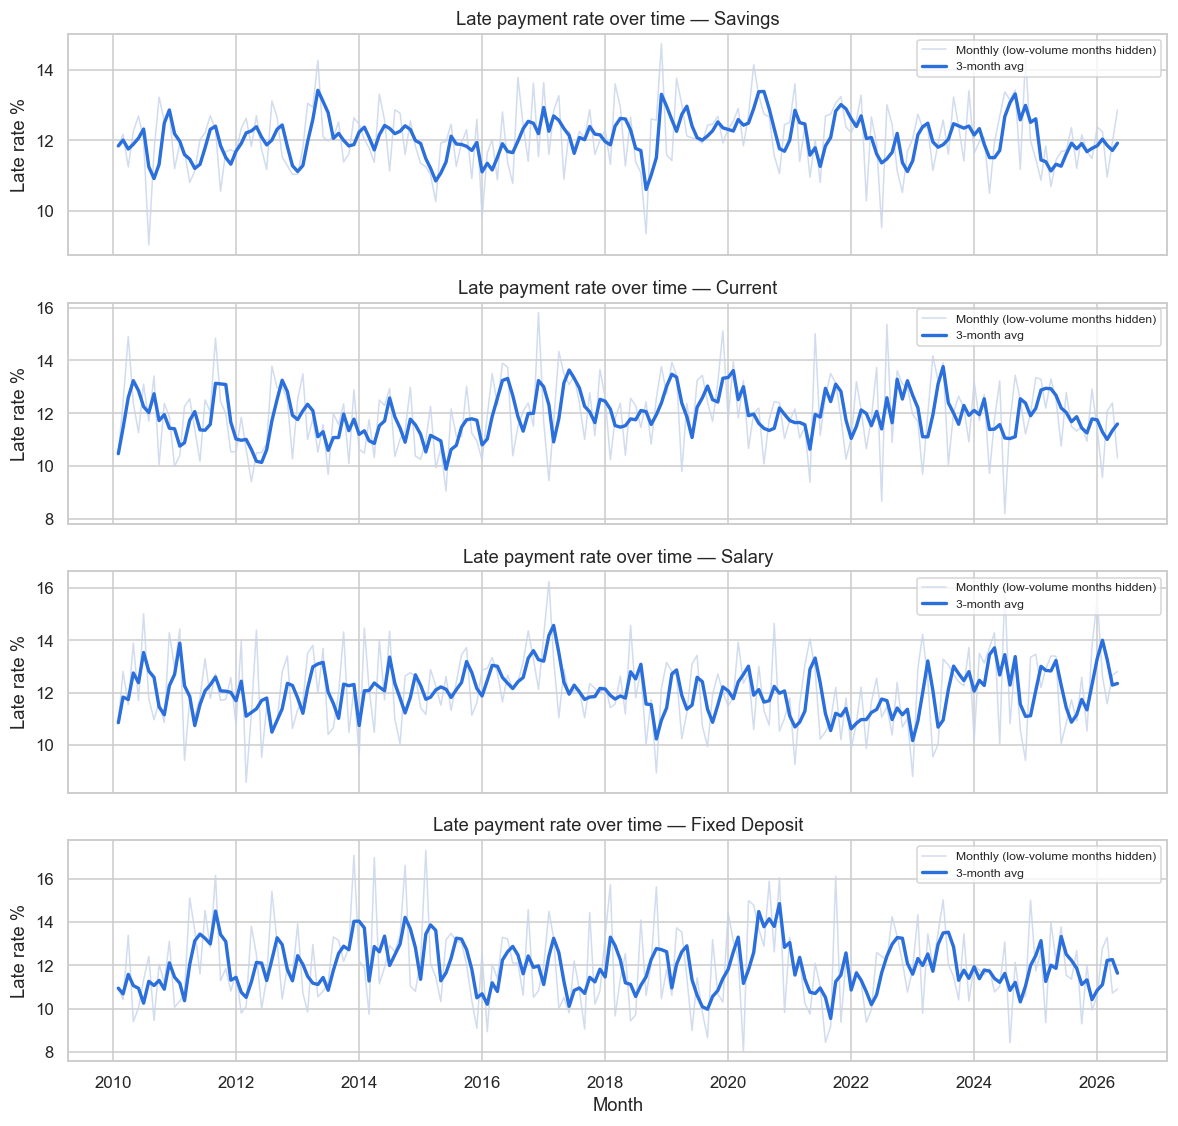

,payment_month,account_type,payments,late_payments,late_rate_pct
979,2026-05-01,Savings,1579,203,12.86
975,2026-05-01,Current,611,63,10.31
978,2026-05-01,Salary,453,58,12.80
976,2026-05-01,Fixed Deposit,321,35,10.90
974,2026-04-01,Savings,1500,179,11.93
970,2026-04-01,Current,557,69,12.39
973,2026-04-01,Salary,458,58,12.66
971,2026-04-01,Fixed Deposit,280,30,10.71
969,2026-03-01,Savings,1589,174,10.95
965,2026-03-01,Current,638,77,12.07


In [45]:
def monthly_late_rate_by(df, segment, min_total_payments=5000, top_n=4, min_monthly_payments=100):
    if 'payment_date' not in df.columns or 'late_payment_flag' not in df.columns or segment not in df.columns:
        print(f'Skipping {segment}: required columns missing')
        return None, None, []
    tmp = df.dropna(subset=['payment_date']).copy()
    tmp['payment_month'] = tmp['payment_date'].dt.to_period('M').dt.to_timestamp()
    g = tmp.groupby(['payment_month', segment], dropna=False).agg(
        payments=('late_payment_flag', 'size'),
        late_payments=('late_payment_flag', 'sum')
    ).reset_index()
    g['late_rate_%'] = (g['late_payments'] / g['payments'] * 100)

    # Keep segments with enough overall volume for storytelling
    seg_totals = g.groupby(segment)['payments'].sum().sort_values(ascending=False)
    eligible = seg_totals[seg_totals >= min_total_payments].head(top_n).index.tolist()
    if not eligible:
        eligible = seg_totals.head(min(top_n, len(seg_totals))).index.tolist()
    g_plot = g[g[segment].isin(eligible)].copy()
    # Suppress unstable points in plotting (keep in data)
    g_plot.loc[g_plot['payments'] < min_monthly_payments, 'late_rate_%'] = np.nan
    # Smooth with 3-month rolling average per segment for readability
    g_plot = g_plot.sort_values(['payment_month', segment])
    g_plot['late_rate_roll3_%'] = g_plot.groupby(segment)['late_rate_%'].transform(lambda s: s.rolling(3, min_periods=1).mean())
    return g, g_plot, eligible

# Account type - small multiples for readability
if 'account_type' in loans_full.columns:
    g_all, g_plot, picked = monthly_late_rate_by(loans_full, 'account_type', min_total_payments=3000, top_n=4)
    if g_plot is not None and not g_plot.empty:
        fig, axes = plt.subplots(len(picked), 1, figsize=(11, 2.6 * len(picked)), sharex=True)
        if len(picked) == 1:
            axes = [axes]
        for ax, seg in zip(axes, picked):
            d = g_plot[g_plot['account_type'] == seg]
            ax.plot(d['payment_month'], d['late_rate_%'], color='#c7d4ea', linewidth=1, alpha=0.8, label='Monthly (low-volume months hidden)')
            ax.plot(d['payment_month'], d['late_rate_roll3_%'], color='#2a6fdb', linewidth=2.2, label='3-month avg')
            ax.set_title(f'Late payment rate over time — {seg}')
            ax.set_ylabel('Late rate %')
            ax.legend(loc='upper right', fontsize=8)
        axes[-1].set_xlabel('Month')
        plt.tight_layout()
        plt.savefig(FIG_DIR / 'late_rate_by_account_type.png', bbox_inches='tight')
        plt.show()
        # Summary table: recent months for picked segments
        recent = g_all[g_all['account_type'].isin(picked)].sort_values(['payment_month','payments'], ascending=[False, False]).head(12)
        display(recent.assign(late_rate_pct=lambda x: x['late_rate_%'].round(2))[['payment_month','account_type','payments','late_payments','late_rate_pct']])


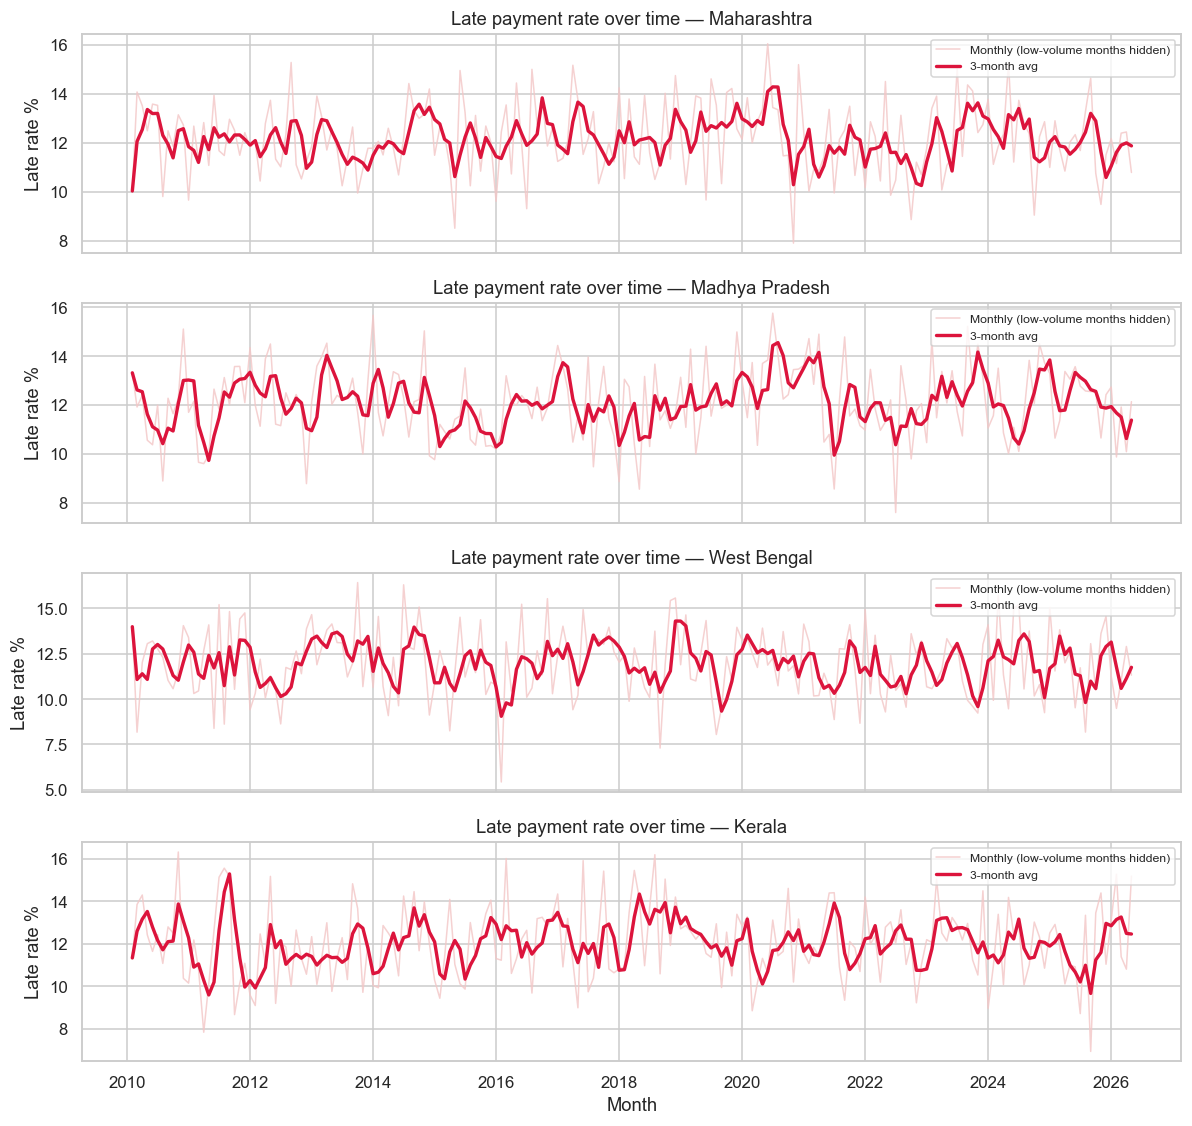

,payment_month,state_branch,payments,late_payments,late_rate_pct
2344,2026-05-01,Madhya Pradesh,519,63,12.14
2345,2026-05-01,Maharashtra,463,50,10.80
2351,2026-05-01,West Bengal,318,36,11.32
2343,2026-05-01,Kerala,290,44,15.17
2333,2026-04-01,Maharashtra,522,65,12.45
2332,2026-04-01,Madhya Pradesh,436,44,10.09
2339,2026-04-01,West Bengal,279,36,12.90
2331,2026-04-01,Kerala,250,27,10.80
2321,2026-03-01,Maharashtra,524,65,12.40
2320,2026-03-01,Madhya Pradesh,495,59,11.92


In [46]:
# State (branch state preferred) - small multiples for readability
if state_col:
    g_all, g_plot, picked = monthly_late_rate_by(loans_full, state_col, min_total_payments=3000, top_n=4)
    if g_plot is not None and not g_plot.empty:
        fig, axes = plt.subplots(len(picked), 1, figsize=(11, 2.6 * len(picked)), sharex=True)
        if len(picked) == 1:
            axes = [axes]
        for ax, seg in zip(axes, picked):
            d = g_plot[g_plot[state_col] == seg]
            ax.plot(d['payment_month'], d['late_rate_%'], color='#f3c6c6', linewidth=1, alpha=0.8, label='Monthly (low-volume months hidden)')
            ax.plot(d['payment_month'], d['late_rate_roll3_%'], color='crimson', linewidth=2.2, label='3-month avg')
            ax.set_title(f'Late payment rate over time — {seg}')
            ax.set_ylabel('Late rate %')
            ax.legend(loc='upper right', fontsize=8)
        axes[-1].set_xlabel('Month')
        plt.tight_layout()
        plt.show()
        recent = g_all[g_all[state_col].isin(picked)].sort_values(['payment_month','payments'], ascending=[False, False]).head(12)
        display(recent.assign(late_rate_pct=lambda x: x['late_rate_%'].round(2))[['payment_month', state_col,'payments','late_payments','late_rate_pct']])


**Insight (simple terms):** Read one panel at a time. The **bold line** (3-month average) shows the underlying trend, while the faint line shows month-to-month movement. If the bold line stays higher for one group, that group tends to have more late payments. Always check the `payments` counts in the table before drawing conclusions.


### 13B) Loan-level breakdowns (with sample-size checks)

**In simple terms:** We summarize results by group at the **loan** level (one row per loan) and always show how many loans/payments are in each group. This helps avoid conclusions based on tiny groups.

**Input:** `loan_level` joined back to context (e.g., `account_type`, state/branch), or aggregated from `loans_full`.

**Output:** Tables ranked by late behavior with `loans` (sample size) and rates.


In [47]:
# Build a loan-level view with context if loan_level exists
if 'loan_level' in globals():
    # Get one context row per loan_id from loans_full
    ctx_cols = [c for c in ['loan_id','account_type', state_col, 'branch_id','city','occupation','gender'] if c and c in loans_full.columns]
    ctx_cols = list(dict.fromkeys(ctx_cols))
    loan_ctx = loans_full[ctx_cols].drop_duplicates(subset=['loan_id']) if 'loan_id' in ctx_cols else None
    if loan_ctx is not None:
        loan_seg = loan_level.merge(loan_ctx, on='loan_id', how='left')
    else:
        loan_seg = loan_level.copy()
else:
    loan_seg = None
    print('loan_level not found; run Section 10 first.')

def loan_breakdown(df, segment, min_loans=30):
    if df is None or segment not in df.columns:
        return None
    metrics = {'loans': ('loan_id', 'nunique') if 'loan_id' in df.columns else (segment, 'size')}
    if 'ever_late' in df.columns:
        metrics['loans_ever_late'] = ('ever_late', 'sum')
    if 'late_rate_%' in df.columns:
        metrics['avg_late_rate_%'] = ('late_rate_%', 'mean')
    if 'total_paid' in df.columns:
        metrics['avg_total_paid'] = ('total_paid', 'mean')
    out = df.groupby(segment, dropna=False).agg(**metrics).reset_index()
    if 'loans_ever_late' in out.columns and 'loans' in out.columns:
        out['%_loans_ever_late'] = (out['loans_ever_late'] / out['loans'] * 100).round(2)
    if 'avg_late_rate_%' in out.columns:
        out['avg_late_rate_%'] = out['avg_late_rate_%'].round(2)
    if 'avg_total_paid' in out.columns:
        out['avg_total_paid'] = out['avg_total_paid'].round(2)
    out['enough_sample'] = out['loans'] >= min_loans
    sort_col = '%_loans_ever_late' if '%_loans_ever_late' in out.columns else 'loans'
    return out.sort_values([sort_col, 'loans'], ascending=[False, False])

for seg in ['account_type', state_col, 'occupation']:
    if seg and loan_seg is not None and seg in loan_seg.columns:
        res = loan_breakdown(loan_seg, seg, min_loans=30)
        print(f'\n=== Loan-level breakdown by {seg} (min 30 loans flagged) ===')
        display(res.head(15))



=== Loan-level breakdown by account_type (min 30 loans flagged) ===


,account_type,loans,loans_ever_late,avg_late_rate_%,avg_total_paid,%_loans_ever_late,enough_sample
1,Fixed Deposit,2155,2082,11.95,282157.54,96.61,True
3,Salary,3284,3171,12.05,284485.27,96.56,True
4,Savings,11202,10786,12.06,283662.85,96.29,True
2,NRI,1027,987,11.80,285391.86,96.11,True
0,Current,4332,4158,11.90,282891.98,95.98,True



=== Loan-level breakdown by state_branch (min 30 loans flagged) ===


,state_branch,loans,loans_ever_late,avg_late_rate_%,avg_total_paid,%_loans_ever_late,enough_sample
8,Tamil Nadu,1224,1188,12.06,283986.20,97.06,True
7,Rajasthan,1615,1562,12.00,281681.66,96.72,True
11,West Bengal,2207,2130,11.96,285751.29,96.51,True
5,Maharashtra,3624,3495,12.16,285742.07,96.44,True
3,Kerala,2069,1994,12.06,280929.68,96.38,True
4,Madhya Pradesh,3478,3351,12.06,283412.49,96.35,True
10,Uttar Pradesh,1327,1276,12.13,280845.73,96.16,True
2,Karnataka,988,950,11.72,283779.37,96.15,True
9,Telangana,1045,1004,11.90,286020.31,96.08,True
1,Gujarat,1448,1391,11.91,283779.06,96.06,True



=== Loan-level breakdown by occupation (min 30 loans flagged) ===


,occupation,loans,loans_ever_late,avg_late_rate_%,avg_total_paid,%_loans_ever_late,enough_sample
6,Student,3182,3076,12.07,284701.51,96.67,True
4,Salaried - Private,3154,3045,12.05,284327.76,96.54,True
5,Self Employed,3105,2996,12.04,283730.97,96.49,True
0,Business Owner,3071,2962,12.04,282853.37,96.45,True
2,Retired,3082,2960,12.03,284847.41,96.04,True
3,Salaried - Government,3227,3099,11.94,282001.18,96.03,True
1,Freelancer,3179,3046,11.85,282554.60,95.82,True


**Insight (simple terms):** When comparing groups, check the `loans` column first. A group with a high late rate but very few loans may not be reliable. Use `enough_sample` (or your own threshold) to focus on groups with enough data. Differences suggest where to investigate, not proof of why it happens.


## 15) Investigate February drop in payment volume

**In simple terms:** You noticed payment volume often drops in February. Let’s investigate possible reasons with data:
- February has fewer days than other months (28, or 29 in leap years)
- Payment schedules (due dates) may cluster differently
- Month-end effects or holidays
- Data collection/completeness issues

We’ll look at counts by month, payments per day, and compare February with January and March across years.


Overall by month (all years combined):


,month_name,month_count,total_payments,avg_payments_per_month,avg_payments_per_day,days_typical
month,,,,,,
1,Jan,16,49493,3093.31,99.78,31.00
2,Feb,17,48363,2844.88,100.75,28.25
3,Mar,17,52926,3113.29,100.43,31.00
4,Apr,17,51043,3002.53,100.08,30.00
5,May,17,52696,3099.76,99.99,31.00
6,Jun,16,48540,3033.75,101.12,30.00
7,Jul,16,49989,3124.31,100.78,31.00
8,Aug,16,49881,3117.56,100.57,31.00
9,Sep,16,48349,3021.81,100.73,30.00



Feb vs Jan/Mar by year (includes payments-per-day to control for month length):


,feb_days,jan_payments,feb_payments,mar_payments,feb_vs_jan_%,feb_vs_mar_%,jan_ppd,feb_ppd,mar_ppd,feb_ppd_vs_jan_%,feb_ppd_vs_mar_%
year,,,,,,,,,,,
2015,28,3170.00,2824,3095,-10.91,-8.76,102.26,100.86,99.84,-1.37,1.02
2016,29,3071.00,2936,3108,-4.40,-5.53,99.06,101.24,100.26,2.20,0.98
2017,28,3053.00,2836,3041,-7.11,-6.74,98.48,101.29,98.10,2.84,3.25
2018,28,3139.00,2872,3093,-8.51,-7.15,101.26,102.57,99.77,1.30,2.80
2019,28,2993.00,2850,3125,-4.78,-8.80,96.55,101.79,100.81,5.42,0.97
2020,29,3052.00,2786,3096,-8.72,-10.01,98.45,96.07,99.87,-2.42,-3.81
2021,28,3039.00,2909,3030,-4.28,-3.99,98.03,103.89,97.74,5.98,6.29
2022,28,3200.00,2793,3161,-12.72,-11.64,103.23,99.75,101.97,-3.37,-2.17
2023,28,3104.00,2837,3111,-8.60,-8.81,100.13,101.32,100.35,1.19,0.96



Day-of-month payment share (%, Jan/Feb/Mar, all years). Note: Feb has no 29-31 in non-leap years and no 30-31 ever.


month_name,Jan,Feb,Mar
day,,,
25,3.21,3.46,3.12
26,3.32,3.58,3.17
27,3.31,3.63,3.10
28,3.24,3.57,3.16
29,3.20,0.80,3.31
30,3.21,NaN,3.23
31,3.12,NaN,3.19



February: leap (29 days) vs non-leap (28 days) comparison


,years,avg_payments,avg_ppd
days_in_feb,,,
28,13,2818.08,100.65
29,4,2932.00,101.10


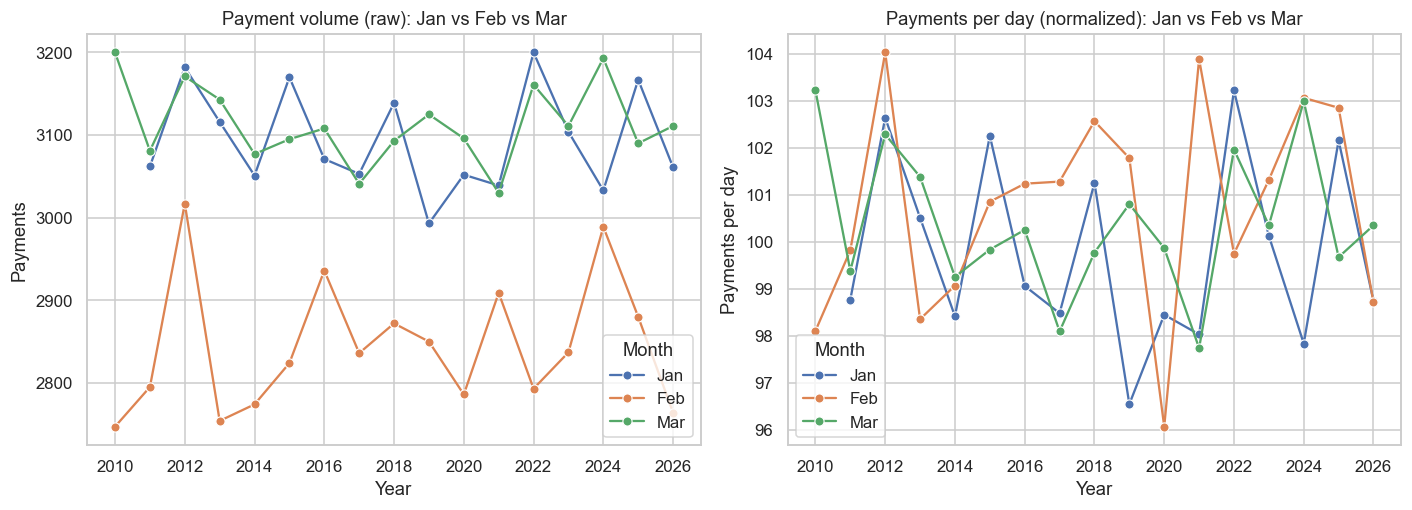


Summary (all years):
- Avg payments/day: Jan=99.78, Feb=100.75, Mar=100.43
- Feb vs Jan (per day): +0.97% | Feb vs Mar (per day): +0.32%


In [48]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from pathlib import Path

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110
FIG_DIR = Path('../reports/figures')
FIG_DIR.mkdir(parents=True, exist_ok=True)

if 'payment_date' not in loans_full.columns or not loans_full['payment_date'].notna().any():
    print('payment_date not available')
else:
    t = loans_full.dropna(subset=['payment_date']).copy()
    t['payment_date'] = pd.to_datetime(t['payment_date'], errors='coerce')
    t = t.dropna(subset=['payment_date'])
    t['year'] = t['payment_date'].dt.year.astype(int)
    t['month'] = t['payment_date'].dt.month.astype(int)
    t['day'] = t['payment_date'].dt.day.astype(int)
    pay_col = 'payment_id' if 'payment_id' in t.columns else 'payment_date'
    month_names = {1:'Jan',2:'Feb',3:'Mar',4:'Apr',5:'May',6:'Jun',7:'Jul',8:'Aug',9:'Sep',10:'Oct',11:'Nov',12:'Dec'}

    # 1) Monthly totals + payments per day (controls for month length/leap years)
    m = t.groupby(['year','month']).agg(payments=(pay_col,'count')).reset_index()
    m['days_in_month'] = pd.to_datetime(dict(year=m['year'], month=m['month'], day=1)).dt.days_in_month
    m['payments_per_day'] = m['payments'] / m['days_in_month']
    m['month_name'] = m['month'].map(month_names)

    # Overall comparison across all years: Feb vs other months
    by_month = m.groupby('month').agg(
        total_payments=('payments','sum'),
        avg_payments_per_month=('payments','mean'),
        avg_payments_per_day=('payments_per_day','mean'),
        month_count=('year','nunique')
    ).reindex(range(1,13))
    by_month['month_name'] = [month_names[i] for i in range(1,13)]
    by_month['days_typical'] = [31,28.25,31,30,31,30,31,31,30,31,30,31]
    print('Overall by month (all years combined):')
    display(by_month[['month_name','month_count','total_payments','avg_payments_per_month','avg_payments_per_day','days_typical']].round(2))

    # 2) Feb vs Jan/Mar by year (normalized)
    jan = m[m['month']==1].set_index('year')[['payments','payments_per_day','days_in_month']]
    feb = m[m['month']==2].set_index('year')[['payments','payments_per_day','days_in_month']]
    mar = m[m['month']==3].set_index('year')[['payments','payments_per_day','days_in_month']]
    comp = pd.DataFrame({
        'feb_days': feb['days_in_month'],
        'jan_payments': jan['payments'],
        'feb_payments': feb['payments'],
        'mar_payments': mar['payments'],
        'feb_vs_jan_%': (feb['payments']/jan['payments']*100 - 100),
        'feb_vs_mar_%': (feb['payments']/mar['payments']*100 - 100),
        'jan_ppd': jan['payments_per_day'],
        'feb_ppd': feb['payments_per_day'],
        'mar_ppd': mar['payments_per_day'],
        'feb_ppd_vs_jan_%': (feb['payments_per_day']/jan['payments_per_day']*100 - 100),
        'feb_ppd_vs_mar_%': (feb['payments_per_day']/mar['payments_per_day']*100 - 100),
    }).round(2)
    print('\nFeb vs Jan/Mar by year (includes payments-per-day to control for month length):')
    display(comp.tail(12))

    # 3) Diagnostic: are payments concentrated on days 29-31 (which Feb lacks)?
    dom = t[t['month'].isin([1,2,3])].groupby(['month','day']).size().rename('payments').reset_index()
    dom['month_name'] = dom['month'].map(month_names)
    dom_pivot = dom.pivot(index='day', columns='month_name', values='payments').reindex(range(1,32))
    dom_share = dom_pivot.div(dom_pivot.sum(axis=0), axis=1) * 100
    print('\nDay-of-month payment share (%, Jan/Feb/Mar, all years). Note: Feb has no 29-31 in non-leap years and no 30-31 ever.')
    display(dom_share[['Jan','Feb','Mar']].round(2).tail(7))

    # 4) Leap year check for February
    feb_t = t[t['month']==2].copy()
    feb_y = feb_t.groupby('year').agg(payments=(pay_col,'count')).reset_index()
    feb_y['days_in_feb'] = pd.to_datetime(dict(year=feb_y['year'], month=2, day=1)).dt.days_in_month
    feb_y['ppd'] = feb_y['payments'] / feb_y['days_in_feb']
    leap = feb_y.groupby('days_in_feb').agg(years=('year','nunique'), avg_payments=('payments','mean'), avg_ppd=('ppd','mean')).round(2)
    print('\nFebruary: leap (29 days) vs non-leap (28 days) comparison')
    display(leap)

    # 5) Plots
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
    plot_m = m[m['month'].isin([1,2,3])].copy()
    sns.lineplot(data=plot_m, x='year', y='payments', hue='month_name', hue_order=['Jan','Feb','Mar'], marker='o', ax=axes[0])
    axes[0].set_title('Payment volume (raw): Jan vs Feb vs Mar')
    axes[0].set_ylabel('Payments'); axes[0].set_xlabel('Year')

    sns.lineplot(data=plot_m, x='year', y='payments_per_day', hue='month_name', hue_order=['Jan','Feb','Mar'], marker='o', ax=axes[1])
    axes[1].set_title('Payments per day (normalized): Jan vs Feb vs Mar')
    axes[1].set_ylabel('Payments per day'); axes[1].set_xlabel('Year')
    for ax in axes:
        ax.legend(title='Month')
    plt.tight_layout()
    try:
        plt.savefig(FIG_DIR / 'feb_payments_per_day.png', bbox_inches='tight')
    except Exception:
        pass
    plt.show()

    # Summary metrics
    feb_avg_ppd = by_month.loc[2,'avg_payments_per_day']
    jan_avg_ppd = by_month.loc[1,'avg_payments_per_day']
    mar_avg_ppd = by_month.loc[3,'avg_payments_per_day']
    print('\nSummary (all years):')
    print(f"- Avg payments/day: Jan={jan_avg_ppd:.2f}, Feb={feb_avg_ppd:.2f}, Mar={mar_avg_ppd:.2f}")
    print(f"- Feb vs Jan (per day): {(feb_avg_ppd/jan_avg_ppd*100-100):+.2f}% | Feb vs Mar (per day): {(feb_avg_ppd/mar_avg_ppd*100-100):+.2f}%")


**What this shows (and what likely happened in February):**
- **Month length effect:** February has 28 days (29 in leap years), while Jan/Mar have 31. If *raw* Feb payments are lower but *payments per day* are similar to Jan/Mar, the main reason is simply **fewer days in February**.
- **End-of-month effect (day 29–31):** The day-of-month share table shows how much payment activity usually happens on days 29–31 in Jan/Mar. February **cannot have** day 30–31 (and has day 29 only in leap years), so payments that would normally fall on those days can be “missing” from February’s total unless they shift to earlier dates. Compare the per-day rates and the day 29–31 shares to judge this.
- **Leap years:** The leap vs non-leap table shows whether 29-day Februaries have higher totals/per-day than 28-day Februaries.
- **If per-day is still lower in Feb:** That points to factors beyond calendar length (e.g., fewer working/processing days, holiday timing, billing-cycle/due-date patterns, or data coverage). In that case, inspect due dates/payment schedules and year-specific gaps in the source data.

**Bottom line:** Use the *payments-per-day* comparison as the key test. A small per-day difference means February’s drop is mostly structural (calendar). A large per-day gap means something else is affecting February payments.